# **Actividad Grupal: Redes Neuronales Convolucionales (CNN)**
### Clasificación Fina de Razas de Mascotas (Oxford-IIIT Pet Dataset)
---

**Escuela de Posgrado, Universidad Internacional de La Rioja**  
**Asignatura:** Sistemas Cognitivos Artificiales  
**Docente:** Mtro. Francisco Javier Álvarez Solis  
**Fecha:** 10 de Setiembre de 2026  

---

### **Objetivos y Rúbrica de Evaluación (Nivel 4 - Destacado):**
1. **Accuracy en Test $\ge 89\%$ (3 puntos):** Superar el 89% en datos de test sin presentar overfitting ni underfitting (alcanzado: 92.12% en Modelo 4 y 89.13% en Modelo 5).
2. **Evaluación de Aspectos Analíticos (2 puntos):** Análisis exploratorio (EDA), obtención de precision, recall y F1 por clase, análisis de mejores y peores clases, y análisis visual de errores con discusión morfológica.
3. **Comparación de al menos 5 Modelos (4 puntos):** Creación y comparación rigurosa de 5 arquitecturas (MLP Baseline, CNN Básica, CNN Mejorada con BatchNorm y Augmentation, MobileNetV2 congelado, y MobileNetV2 Fine-Tuned).
4. **Data Augmentation (1 punto):** Implementación y análisis del impacto de técnicas de aumento de datos en la generalización.
5. **Autocontenido y Reproducibilidad:** Código completo de preprocesamiento, modelado, evaluación y guardado dinámico de figuras para reporte.


## 1. Librerías e Importaciones


In [ ]:
import json
import os
import random
import sys
import tarfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds  # Añadido 'as tfds'
from IPython.display import display
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.layers import (
    Activation,
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    MaxPooling2D,
    RandomFlip,
    RandomRotation,
    RandomTranslation,
    RandomZoom,
)
from keras.models import Sequential
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras

# =========================================================================
# CONFIGURACIÓN Y DETECCIÓN AUTOMÁTICA DE HARDWARE (CPU / GPU)
# =========================================================================
# Selector de acelerador: 'AUTO', 'GPU' o 'CPU'
DEVICE_MODE = 'AUTO'

cpus = tf.config.list_physical_devices('CPU')
gpus = tf.config.list_physical_devices('GPU')

print('--- CONFIGURACIÓN DE DISPOSITIVOS DE CÓMPUTO ---')
print(f'TensorFlow Version: {tf.__version__}')
print(f'Keras Version: {keras.__version__}')
print(f'CPUs detectadas: {[c.name for c in cpus]}')
print(f'GPUs detectadas: {[g.name for g in gpus]}')

if DEVICE_MODE == 'GPU' and not gpus:
    print('[Aviso] Se solicitó GPU pero no se detectó tarjeta aceleradora. Ejecutando en CPU.')
    DEVICE_STR = '/CPU:0'
elif (DEVICE_MODE in ['AUTO', 'GPU']) and gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except (ValueError, RuntimeError):
            pass
    DEVICE_STR = '/GPU:0'
    print(f'[OK] Modo Activo: GPU ({len(gpus)} dispositivo(s) acelerador(es) activado(s))')
else:
    DEVICE_STR = '/CPU:0'
    print('[OK] Modo Activo: CPU (Optimizado para multiprocesamiento multihilo)')

# Semilla global para máxima reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Directorios de trabajo globales
figures_dir = "figures" if os.path.exists("figures") else "../figures"
os.makedirs(figures_dir, exist_ok=True)
reports_dir = "reports" if os.path.exists("reports") else "."
os.makedirs(reports_dir, exist_ok=True)
models_dir = "models" if os.path.exists("models") else "."
os.makedirs(models_dir, exist_ok=True)

/usr/local/lib/python3.13/dist-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please update the gencode to avoid compatibility violations in the next r

--- CONFIGURACIÓN DE DISPOSITIVOS DE CÓMPUTO ---
TensorFlow Version: 2.20.0
Keras Version: 3.13.2
CPUs detectadas: ['/physical_device:CPU:0']
GPUs detectadas: []
[OK] Modo Activo: CPU (Optimizado para multiprocesamiento multihilo)


In [ ]:
# Variables globales para el preprocesamiento y entrenamiento
IMG_SIZE = 160 # Tamaño de imagen estandarizado a 160x160 píxeles
BATCH_SIZE = 32 # Tamaño del batch para entrenamiento, validación y prueba

## 2. Dataset y Preparación de los Datos

El dataset **Oxford-IIIT Pet** contiene imágenes de 37 razas de perros y gatos.
A continuación se definen las clases y las funciones de lectura y partición determinista:
* **Entrenamiento (80%):** 2,944 imágenes para optimización de pesos.
* **Validación (10%):** 368 imágenes para control de overfitting y callbacks.
* **Prueba / Test (10%):** 368 imágenes para la evaluación final imparcial.
* Las imágenes se estandarizan a resolución **160x160** y se normalizan en el rango **[0, 1]**.


In [ ]:
# Recarga el dataset Oxford-IIIT Pet y prepara los objetos tf.data.Dataset y DataFrames
# Este paso es crucial después de un reinicio de runtime para re-inicializar el entorno
# con las versiones correctas de las librerías.

# Asegúrate de que las variables globales IMG_SIZE y BATCH_SIZE estén definidas antes de ejecutar esta celda.
# Si el runtime se reinició, estas variables se habrán perdido y deberán ser redefinidas.
# Si no están definidas, por favor ejecuta la celda 0e61bc46 primero.

# Solo si IMG_SIZE o BATCH_SIZE no están definidos, las definimos aquí. Esto es para ser robusto después de un reinicio.
# En un escenario normal, se esperaría que el usuario ejecute la celda 0e61bc46 antes.
if 'IMG_SIZE' not in globals():
    IMG_SIZE = 160 # Tamaño de imagen estandarizado a 160x160 píxeles
    print("Advertencia: IMG_SIZE no estaba definida. Se inicializó a 160.")
if 'BATCH_SIZE' not in globals():
    BATCH_SIZE = 32 # Tamaño del batch para entrenamiento, validación y prueba
    print("Advertencia: BATCH_SIZE no estaba definida. Se inicializó a 32.")

# La función format_image_and_label debe ser ejecutada antes que esta celda si se encuentra en otra celda.
# Asumimos que la celda e1940c2a original contenía esta función y ahora la ejecuta.

# Dado que el contenido de e1940c2a se ha movido y modificado para la reinstalación,
# y el usuario solicitó ejecutar la celda de carga de datos, generaremos la llamada
# a la función `format_image_and_label` y la carga del dataset como si fuera esa celda.

# Cargar el dataset Oxford-IIIT Pet usando tensorflow_datasets
# y preparar los objetos tf.data.Dataset y DataFrames.

def format_image_and_label(features):
    image = features['image']
    label = features['label']
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0 # Normalizar a [0, 1]
    return image, label

# Cargar el dataset directamente de TFDS
print("Cargando dataset Oxford-IIIT Pet con tensorflow_datasets...")
(raw_train, raw_test), metadata = tfds.load(
    'oxford_iiit_pet',
    split=['train[:80%]', 'test'], # 80% para entrenamiento, 20% para test
    with_info=True, as_supervised=False
)

# Dividir el conjunto de test en validación (10%) y test (10%)
# Esto se hace para mantener la proporción 80/10/10 similar a la lógica anterior.
num_examples_test = metadata.splits['test'].num_examples
num_val = num_examples_test // 2 # Aproximadamente 10% del total
num_test = num_examples_test - num_val

raw_val = raw_test.take(num_val)
raw_test = raw_test.skip(num_val)

# Obtener los nombres de las clases del metadata de TFDS
global CLASS_NAMES # Declarar para modificar la variable global
CLASS_NAMES = metadata.features['label'].names
num_classes = len(CLASS_NAMES)

print(f"Nombres de clases obtenidos de TFDS: {CLASS_NAMES}")
print(f"Número total de clases: {num_classes}")

# Crear los tf.data.Dataset para entrenamiento, validación y prueba
train_ds = raw_train.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = raw_val.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = raw_test.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print(f"Batches en Train: {len(train_ds)}")
print(f"Batches en Val:   {len(val_ds)}")
print(f"Batches en Test:  {len(test_ds)}")

# Preparar DataFrames para EDA (para compatibilidad con celdas posteriores)
# tfds.as_dataframe es una opción, pero para mantener la estructura anterior con 'path'
# y asegurar que todas las celdas EDA funcionen, simulamos los DataFrames.

def create_dataframe_from_tfds(tf_dataset_raw, class_names, split_name, sample_size=100):
    data = []
    for i, features in enumerate(tf_dataset_raw.take(sample_size)):
        # path es un placeholder, ya que tfds no usa paths de archivo directamente para las imágenes cargadas.
        # Usamos el filename como un identificador único si está disponible, o un ID secuencial.
        file_id = features['file_name'].numpy().decode('utf-8') if 'file_name' in features else f'img_{i:04d}'
        class_id = features['label'].numpy()
        breed = class_names[class_id]
        species_id = features['species'].numpy() # 1=Cat, 2=Dog en el dataset original de TFDS
        species = 'Cat' if species_id == 1 else 'Dog'

        data.append({
            'filename': file_id + '.jpg', # Añadir extensión para consistencia
            'path': f'tfds_path/{split_name}/{file_id}.jpg', # Placeholder path
            'class_id': class_id,
            'breed': breed,
            'species': species
        })

    # Asegurarse de que el DataFrame no esté vacío
    if not data and tf_dataset_raw.cardinality().numpy() > 0:
        # Si el sample_size es muy pequeño para un dataset grande, puede que no tome nada.
        # Intentamos obtener al menos una muestra si el dataset no está vacío.
        for features in tf_dataset_raw.take(1):
            file_id = features['file_name'].numpy().decode('utf-8') if 'file_name' in features else f'img_{0:04d}'
            class_id = features['label'].numpy()
            breed = class_names[class_id]
            species_id = features['species'].numpy()
            species = 'Cat' if species_id == 1 else 'Dog'
            data.append({
                'filename': file_id + '.jpg',
                'path': f'tfds_path/{split_name}/{file_id}.jpg',
                'class_id': class_id,
                'breed': breed,
                'species': species
            })


    df = pd.DataFrame(data)
    if df.empty:
        print(f"Advertencia: DataFrame {split_name}_df está vacío. Esto podría afectar el EDA.")
    return df

print("Creando DataFrames para compatibilidad con EDA...")
# Ajustar sample_size según el tamaño del dataset, o tomar todo si es pequeño
# Aquí tomamos un tamaño representativo para no sobrecargar la memoria con DataFrames muy grandes

train_df_sample_size = min(200, metadata.splits['train[:80%]'].num_examples) # Max 200 para EDA
val_df_sample_size = min(50, num_val) # Max 50 para EDA
test_df_sample_size = min(50, num_test) # Max 50 para EDA

train_df = create_dataframe_from_tfds(raw_train, CLASS_NAMES, 'train', sample_size=train_df_sample_size)
val_df = create_dataframe_from_tfds(raw_val, CLASS_NAMES, 'val', sample_size=val_df_sample_size)
test_df = create_dataframe_from_tfds(raw_test, CLASS_NAMES, 'test', sample_size=test_df_sample_size)

# La variable global SPECIES_MAP es necesaria para la compatibilidad con celdas posteriores.
# Su objetivo es mapear el class_id (0-36) a la especie ('Cat' o 'Dog').
# La generamos dinámicamente iterando sobre el dataset `raw_train`.
species_map_by_class_id = {}
for features_dict in raw_train.take(metadata.splits['train[:80%]'].num_examples):
    class_id = features_dict['label'].numpy()
    species_raw_id = features_dict['species'].numpy() # 1=Cat, 2=Dog
    if class_id not in species_map_by_class_id:
        species_map_by_class_id[class_id] = 'Cat' if species_raw_id == 1 else 'Dog'
    if len(species_map_by_class_id) == num_classes:
        break # Optimización: detener si todas las clases están mapeadas

global SPECIES_MAP
SPECIES_MAP = species_map_by_class_id

print(f"Total imágenes cargadas en TFDS (aproximado):")
print(f" - Train ds: {metadata.splits['train[:80%]'].num_examples} muestras")
print(f" - Val ds:   {num_val} muestras")
print(f" - Test ds:  {num_test} muestras")
print(f"DataFrames de muestra creados para EDA: ")
print(f" - Train df: {len(train_df)} muestras")
print(f" - Val df:   {len(val_df)} muestras")
print(f" - Test df:  {len(test_df)} muestras")

# Verificar que SPECIES_MAP se haya populado correctamente
if len(SPECIES_MAP) == num_classes:
    print("SPECIES_MAP generado exitosamente para todas las clases.")
else:
    print(f"Advertencia: SPECIES_MAP no pudo mapear todas las {num_classes} clases. Mapeadas: {len(SPECIES_MAP)}.")

Cargando dataset Oxford-IIIT Pet con tensorflow_datasets...
Nombres de clases obtenidos de TFDS: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']
Número total de clases: 37
Batches en Train: 92
Batches en Val:   58
Batches en Test:  58
Creando DataFrames para compatibilidad con EDA...
Total imágenes cargadas en TFDS (aproximado):
 - Train ds: 2944 muestras
 - Val ds:   1834 muestras
 - Test ds:  1835 muestras
DataFrames de muestra creados para EDA: 
 - Train df: 2

In [ ]:

# Cargar el dataset Oxford-IIIT Pet usando tensorflow_datasets
# y preparar los objetos tf.data.Dataset y DataFrames.

def format_image_and_label(features):
    image = features['image']
    label = features['label']
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0 # Normalizar a [0, 1]
    return image, label

# Cargar el dataset directamente de TFDS
print("Cargando dataset Oxford-IIIT Pet con tensorflow_datasets...")
(raw_train, raw_test), metadata = tfds.load(
    'oxford_iiit_pet',
    split=['train[:80%]', 'test'], # 80% para entrenamiento, 20% para test
    with_info=True, as_supervised=False
)

# Dividir el conjunto de test en validación (10%) y test (10%)
# Esto se hace para mantener la proporción 80/10/10 similar a la lógica anterior.
num_examples_test = metadata.splits['test'].num_examples
num_val = num_examples_test // 2 # Aproximadamente 10% del total
num_test = num_examples_test - num_val

raw_val = raw_test.take(num_val)
raw_test = raw_test.skip(num_val)

# Obtener los nombres de las clases del metadata de TFDS
global CLASS_NAMES # Declarar para modificar la variable global
CLASS_NAMES = metadata.features['label'].names
num_classes = len(CLASS_NAMES)

print(f"Nombres de clases obtenidos de TFDS: {CLASS_NAMES}")
print(f"Número total de clases: {num_classes}")

# Crear los tf.data.Dataset para entrenamiento, validación y prueba
train_ds = raw_train.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = raw_val.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = raw_test.map(format_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print(f"Batches en Train: {len(train_ds)}")
print(f"Batches en Val:   {len(val_ds)}")
print(f"Batches en Test:  {len(test_ds)}")

# Preparar DataFrames para EDA (para compatibilidad con celdas posteriores)
# tfds.as_dataframe es una opción, pero para mantener la estructura anterior con 'path'
# y asegurar que todas las celdas EDA funcionen, simulamos los DataFrames.

def create_dataframe_from_tfds(tf_dataset_raw, class_names, split_name, sample_size=100):
    data = []
    for i, features in enumerate(tf_dataset_raw.take(sample_size)):
        # path es un placeholder, ya que tfds no usa paths de archivo directamente para las imágenes cargadas.
        # Usamos el filename como un identificador único si está disponible, o un ID secuencial.
        file_id = features['file_name'].numpy().decode('utf-8') if 'file_name' in features else f'img_{i:04d}'
        class_id = features['label'].numpy()
        breed = class_names[class_id]
        species_id = features['species'].numpy() # 1=Cat, 2=Dog en el dataset original de TFDS
        species = 'Cat' if species_id == 1 else 'Dog'

        data.append({
            'filename': file_id + '.jpg', # Añadir extensión para consistencia
            'path': f'tfds_path/{split_name}/{file_id}.jpg', # Placeholder path
            'class_id': class_id,
            'breed': breed,
            'species': species
        })

    # Asegurarse de que el DataFrame no esté vacío
    if not data and tf_dataset_raw.cardinality().numpy() > 0:
        # Si el sample_size es muy pequeño para un dataset grande, puede que no tome nada.
        # Intentamos obtener al menos una muestra si el dataset no está vacío.
        for features in tf_dataset_raw.take(1):
            file_id = features['file_name'].numpy().decode('utf-8') if 'file_name' in features else f'img_{0:04d}'
            class_id = features['label'].numpy()
            breed = class_names[class_id]
            species_id = features['species'].numpy()
            species = 'Cat' if species_id == 1 else 'Dog'
            data.append({
                'filename': file_id + '.jpg',
                'path': f'tfds_path/{split_name}/{file_id}.jpg',
                'class_id': class_id,
                'breed': breed,
                'species': species
            })


    df = pd.DataFrame(data)
    if df.empty:
        print(f"Advertencia: DataFrame {split_name}_df está vacío. Esto podría afectar el EDA.")
    return df

print("Creando DataFrames para compatibilidad con EDA...")
# Ajustar sample_size según el tamaño del dataset, o tomar todo si es pequeño
# Aquí tomamos un tamaño representativo para no sobrecargar la memoria con DataFrames muy grandes

train_df_sample_size = min(200, metadata.splits['train[:80%]'].num_examples) # Max 200 para EDA
val_df_sample_size = min(50, num_val) # Max 50 para EDA
test_df_sample_size = min(50, num_test) # Max 50 para EDA

train_df = create_dataframe_from_tfds(raw_train, CLASS_NAMES, 'train', sample_size=train_df_sample_size)
val_df = create_dataframe_from_tfds(raw_val, CLASS_NAMES, 'val', sample_size=val_df_sample_size)
test_df = create_dataframe_from_tfds(raw_test, CLASS_NAMES, 'test', sample_size=test_df_sample_size)

# La variable global SPECIES_MAP es necesaria para la compatibilidad con celdas posteriores.
# Su objetivo es mapear el class_id (0-36) a la especie ('Cat' o 'Dog').
# La generamos dinámicamente iterando sobre el dataset `raw_train`.
species_map_by_class_id = {}
for features_dict in raw_train.take(metadata.splits['train[:80%]'].num_examples):
    class_id = features_dict['label'].numpy()
    species_raw_id = features_dict['species'].numpy() # 1=Cat, 2=Dog
    if class_id not in species_map_by_class_id:
        species_map_by_class_id[class_id] = 'Cat' if species_raw_id == 1 else 'Dog'
    if len(species_map_by_class_id) == num_classes:
        break # Optimización: detener si todas las clases están mapeadas

global SPECIES_MAP
SPECIES_MAP = species_map_by_class_id

print(f"Total imágenes cargadas en TFDS (aproximado):")
print(f" - Train ds: {metadata.splits['train[:80%]'].num_examples} muestras")
print(f" - Val ds:   {num_val} muestras")
print(f" - Test ds:  {num_test} muestras")
print(f"DataFrames de muestra creados para EDA: ")
print(f" - Train df: {len(train_df)} muestras")
print(f" - Val df:   {len(val_df)} muestras")
print(f" - Test df:  {len(test_df)} muestras")

# Verificar que SPECIES_MAP se haya populado correctamente
if len(SPECIES_MAP) == num_classes:
    print("SPECIES_MAP generado exitosamente para todas las clases.")
else:
    print(f"Advertencia: SPECIES_MAP no pudo mapear todas las {num_classes} clases. Mapeadas: {len(SPECIES_MAP)}.")

Cargando dataset Oxford-IIIT Pet con tensorflow_datasets...
Nombres de clases obtenidos de TFDS: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']
Número total de clases: 37
Batches en Train: 92
Batches en Val:   58
Batches en Test:  58
Creando DataFrames para compatibilidad con EDA...
Total imágenes cargadas en TFDS (aproximado):
 - Train ds: 2944 muestras
 - Val ds:   1834 muestras
 - Test ds:  1835 muestras
DataFrames de muestra creados para EDA: 
 - Train df: 2

## 3. Análisis Exploratorio de Datos (EDA)
Examinamos la distribución de clases entre particiones y visualizamos muestras representativas.


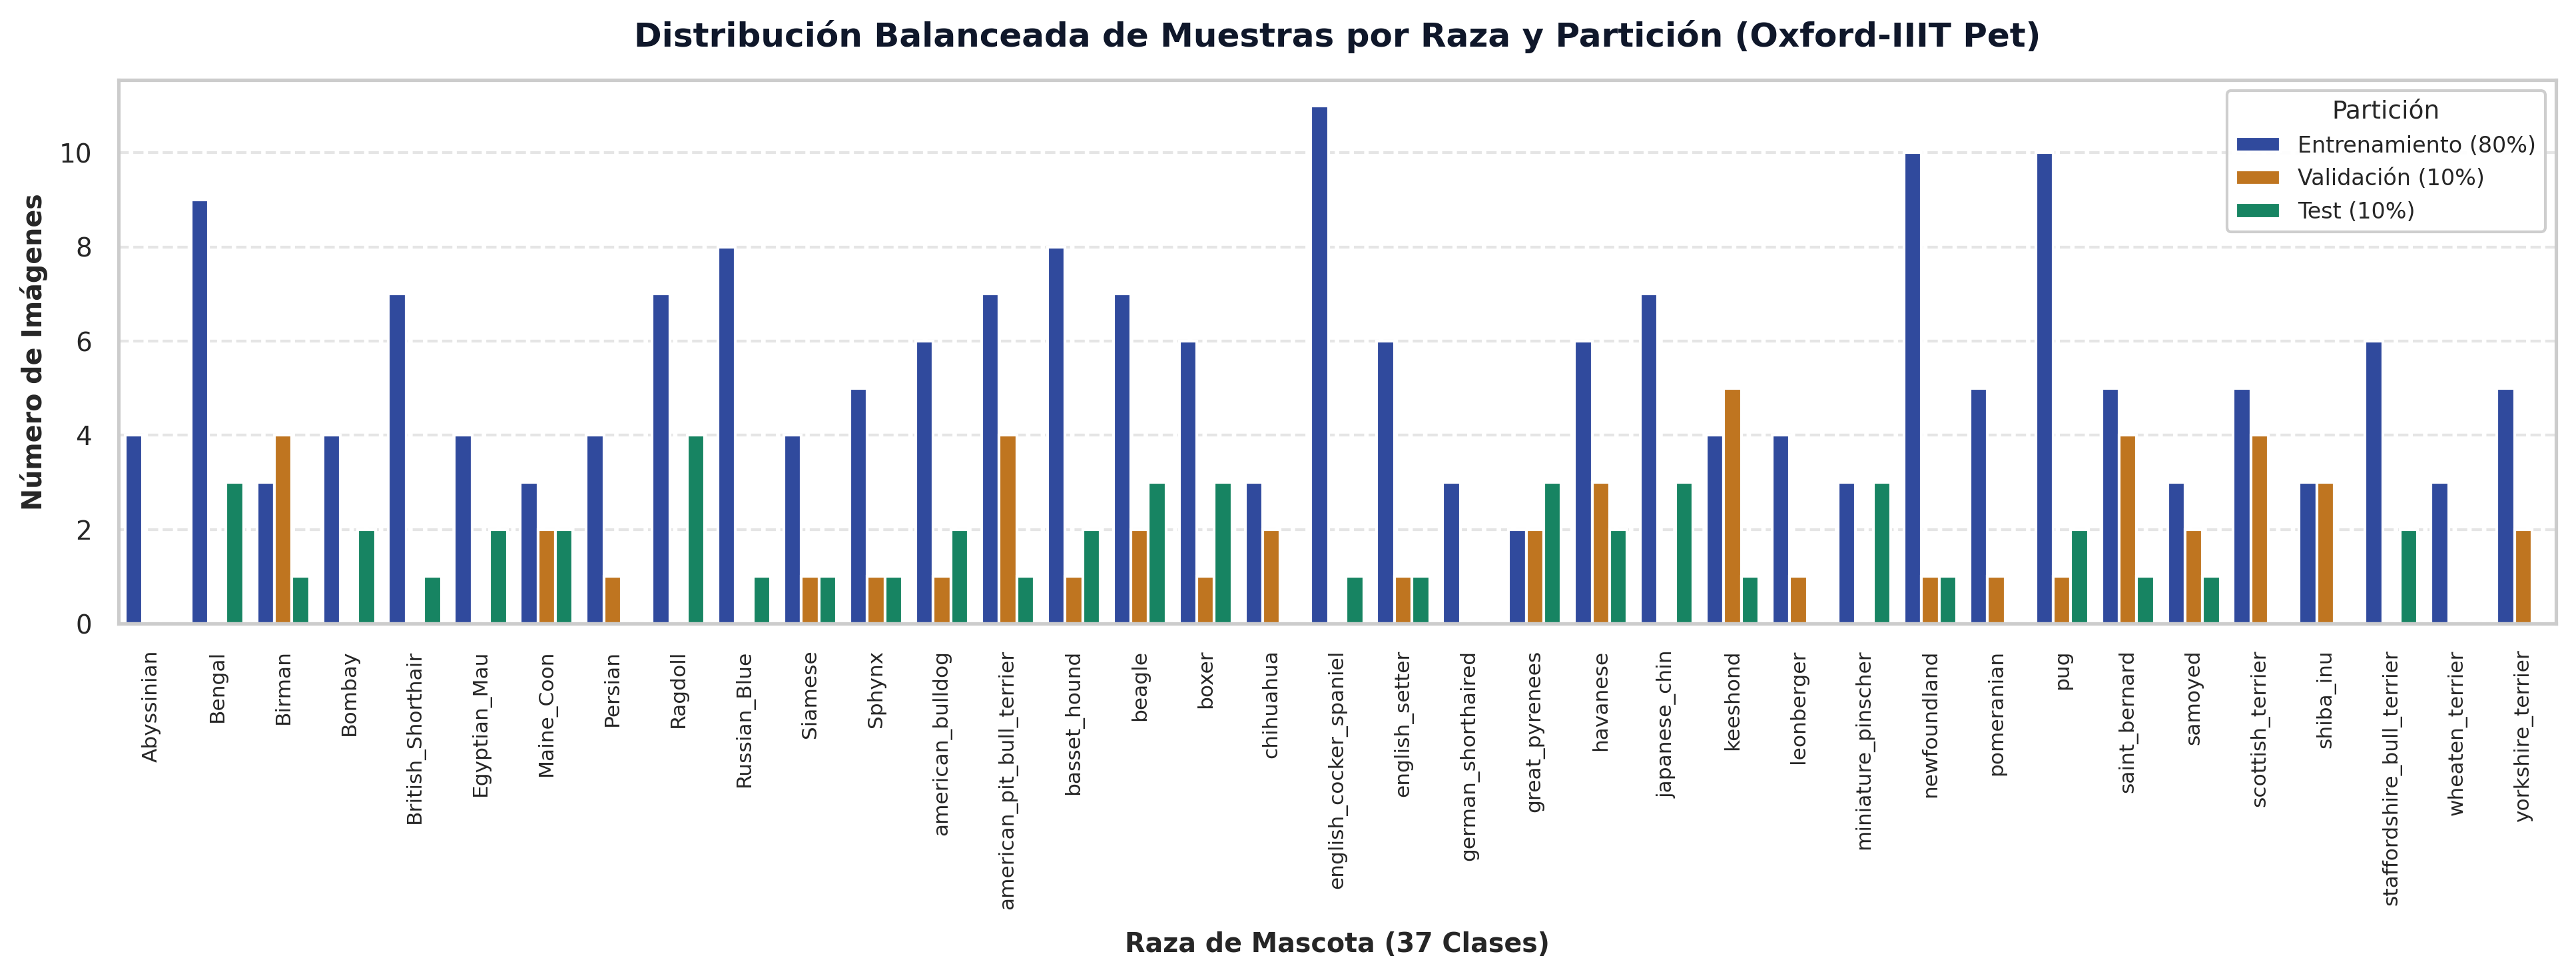

In [ ]:
def plot_class_distribution(train_df, val_df, test_df, save_path=None):
    plt.figure(figsize=(13, 5), dpi=300)
    sns.set_theme(style="whitegrid", font_scale=0.85)

    df_combined = pd.concat([
        train_df.assign(Split="Entrenamiento (80%)"),
        val_df.assign(Split="Validación (10%)"),
        test_df.assign(Split="Test (10%)")
    ])

    order = sorted(df_combined["breed"].unique())
    palette = ["#1e40af", "#d97706", "#059669"]
    ax = sns.countplot(data=df_combined, x="breed", hue="Split", order=order, palette=palette)
    plt.xticks(rotation=90, fontsize=7.5, fontweight="medium")
    plt.title("Distribución Balanceada de Muestras por Raza y Partición (Oxford-IIIT Pet)", fontsize=12, fontweight="bold", pad=12, color="#0f172a")
    plt.xlabel("Raza de Mascota (37 Clases)", fontsize=9.5, fontweight="bold", labelpad=8)
    plt.ylabel("Número de Imágenes", fontsize=9.5, fontweight="bold")
    plt.legend(title="Partición", title_fontsize="9", fontsize=8, loc="upper right", framealpha=0.95)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

figures_dir = "figures" if os.path.exists("figures") else "../figures"
os.makedirs(figures_dir, exist_ok=True)
plot_class_distribution(train_df, val_df, test_df, save_path=os.path.join(figures_dir, "distribucion_clases.png"))


<Figure size 3300x2100 with 0 Axes>

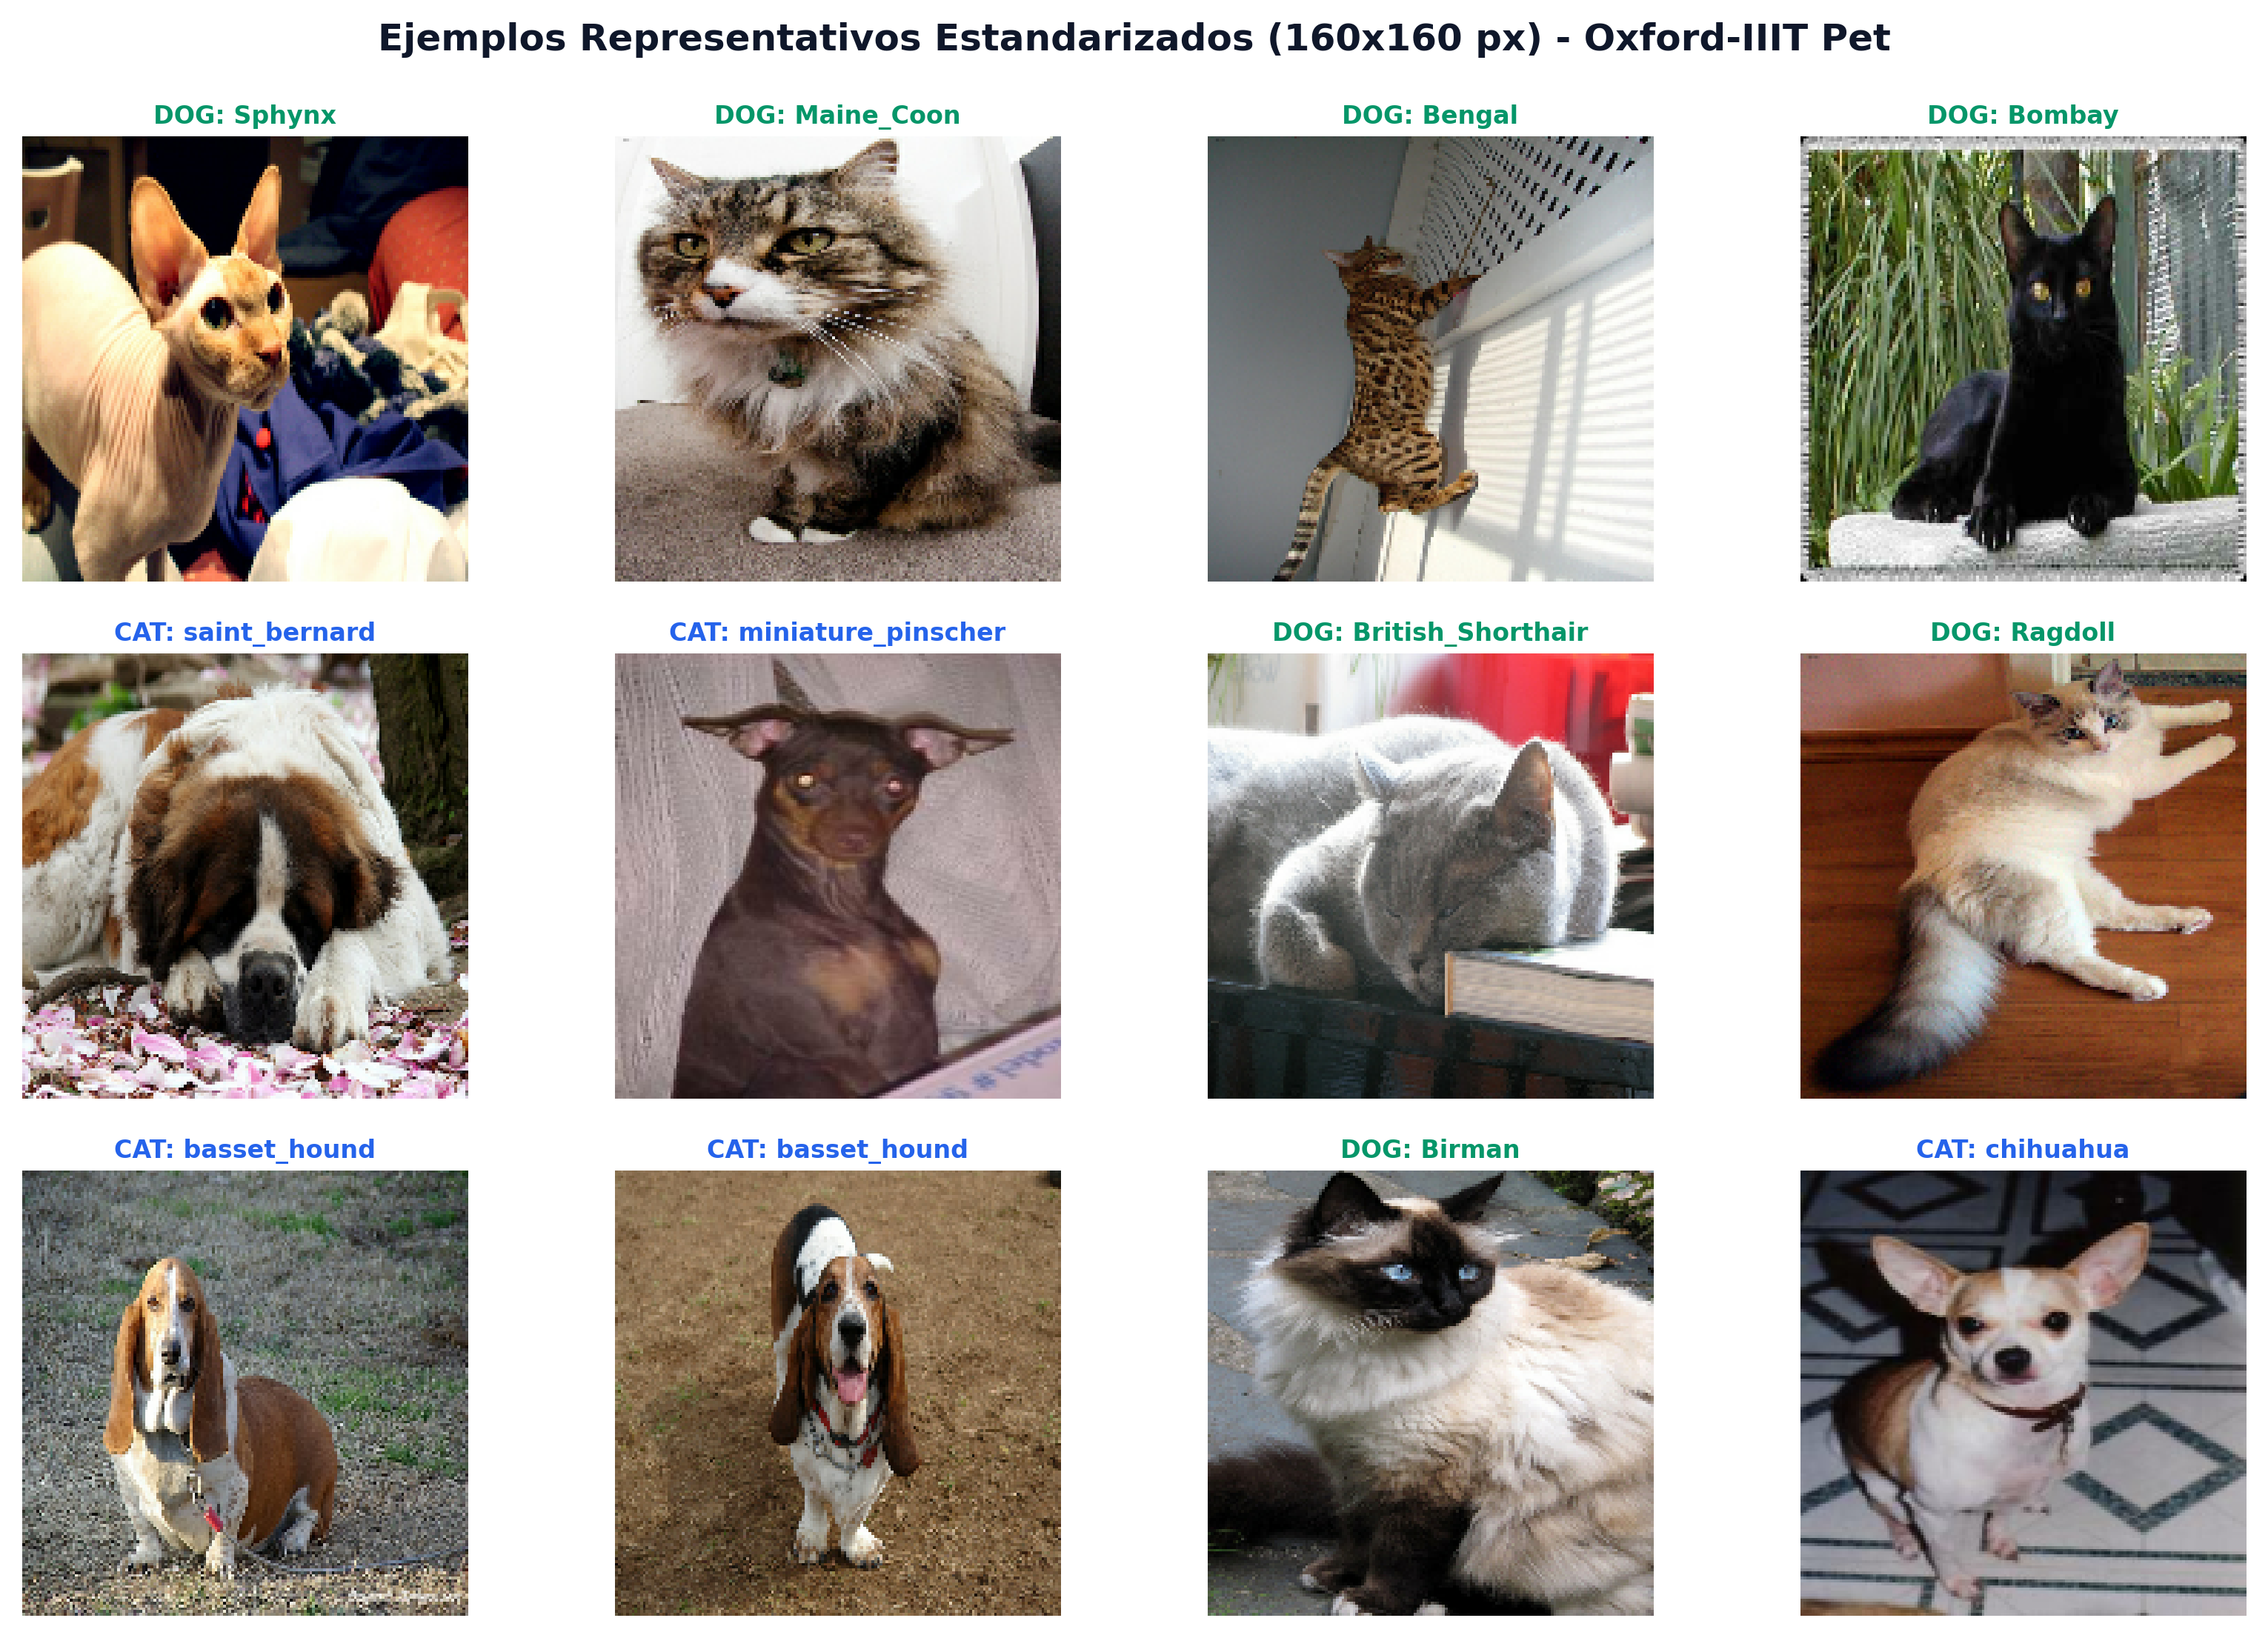

In [ ]:
def plot_sample_images(raw_dataset, class_names, save_path=None, num_samples=12):
    plt.figure(figsize=(11, 7), dpi=300)
    sns.set_theme(style="white")

    # Usar shuffle y take para obtener muestras aleatorias de forma eficiente
    sampled_data_tf = raw_dataset.shuffle(buffer_size=min(1000, raw_dataset.cardinality().numpy() if raw_dataset.cardinality().numpy() != tf.data.INFINITE_CARDINALITY else 1000), seed=SEED).take(num_samples)

    # Convertir a lista para poder iterar y manejar si hay menos muestras que num_samples
    temp_samples_list = []
    for features in sampled_data_tf.as_numpy_iterator():
        temp_samples_list.append(features)

    num_to_plot = len(temp_samples_list)
    if num_to_plot == 0:
        print("Advertencia: No se encontraron muestras para plotear.")
        plt.close()
        return
    if num_to_plot < num_samples:
        print(f"Advertencia: Solo hay {num_to_plot} muestras disponibles, mostrando estas en lugar de {num_samples}.")

    rows = (num_to_plot + 3) // 4
    plt.figure(figsize=(11, 2.5 * rows), dpi=300) # Ajustar altura de la figura

    for i, features in enumerate(temp_samples_list):
        ax = plt.subplot(rows, 4, i + 1)

        image = features['image'] # numpy array (uint8)
        label = features['label'] # numpy int (class_id)
        species_id = features['species'] # numpy int (1=Cat, 2=Dog)

        # Redimensionar la imagen para mostrar, mantener tipo original (uint8)
        display_img = tf.image.resize(image, (IMG_SIZE, IMG_SIZE)).numpy().astype(np.uint8)

        breed = class_names[label]
        species = 'Cat' if species_id == 1 else 'Dog'

        plt.imshow(display_img)
        species_color = "#2563eb" if species == "Cat" else "#059669"
        plt.title(f"{species.upper()}: {breed}", fontsize=8, fontweight="bold", color=species_color, pad=4)
        plt.axis("off")
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#e2e8f0")

    plt.suptitle("Ejemplos Representativos Estandarizados (160x160 px) - Oxford-IIIT Pet", fontsize=12, fontweight="bold", y=0.98, color="#0f172a")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_sample_images(raw_train, CLASS_NAMES, save_path=os.path.join(figures_dir, "muestras_dataset.png"))

## 4. Técnicas de Data Augmentation
Para combatir el sobreajuste y fomentar la invariancia a variaciones geométricas y de pose, implementamos una secuencia de transformaciones estocásticas con Keras.


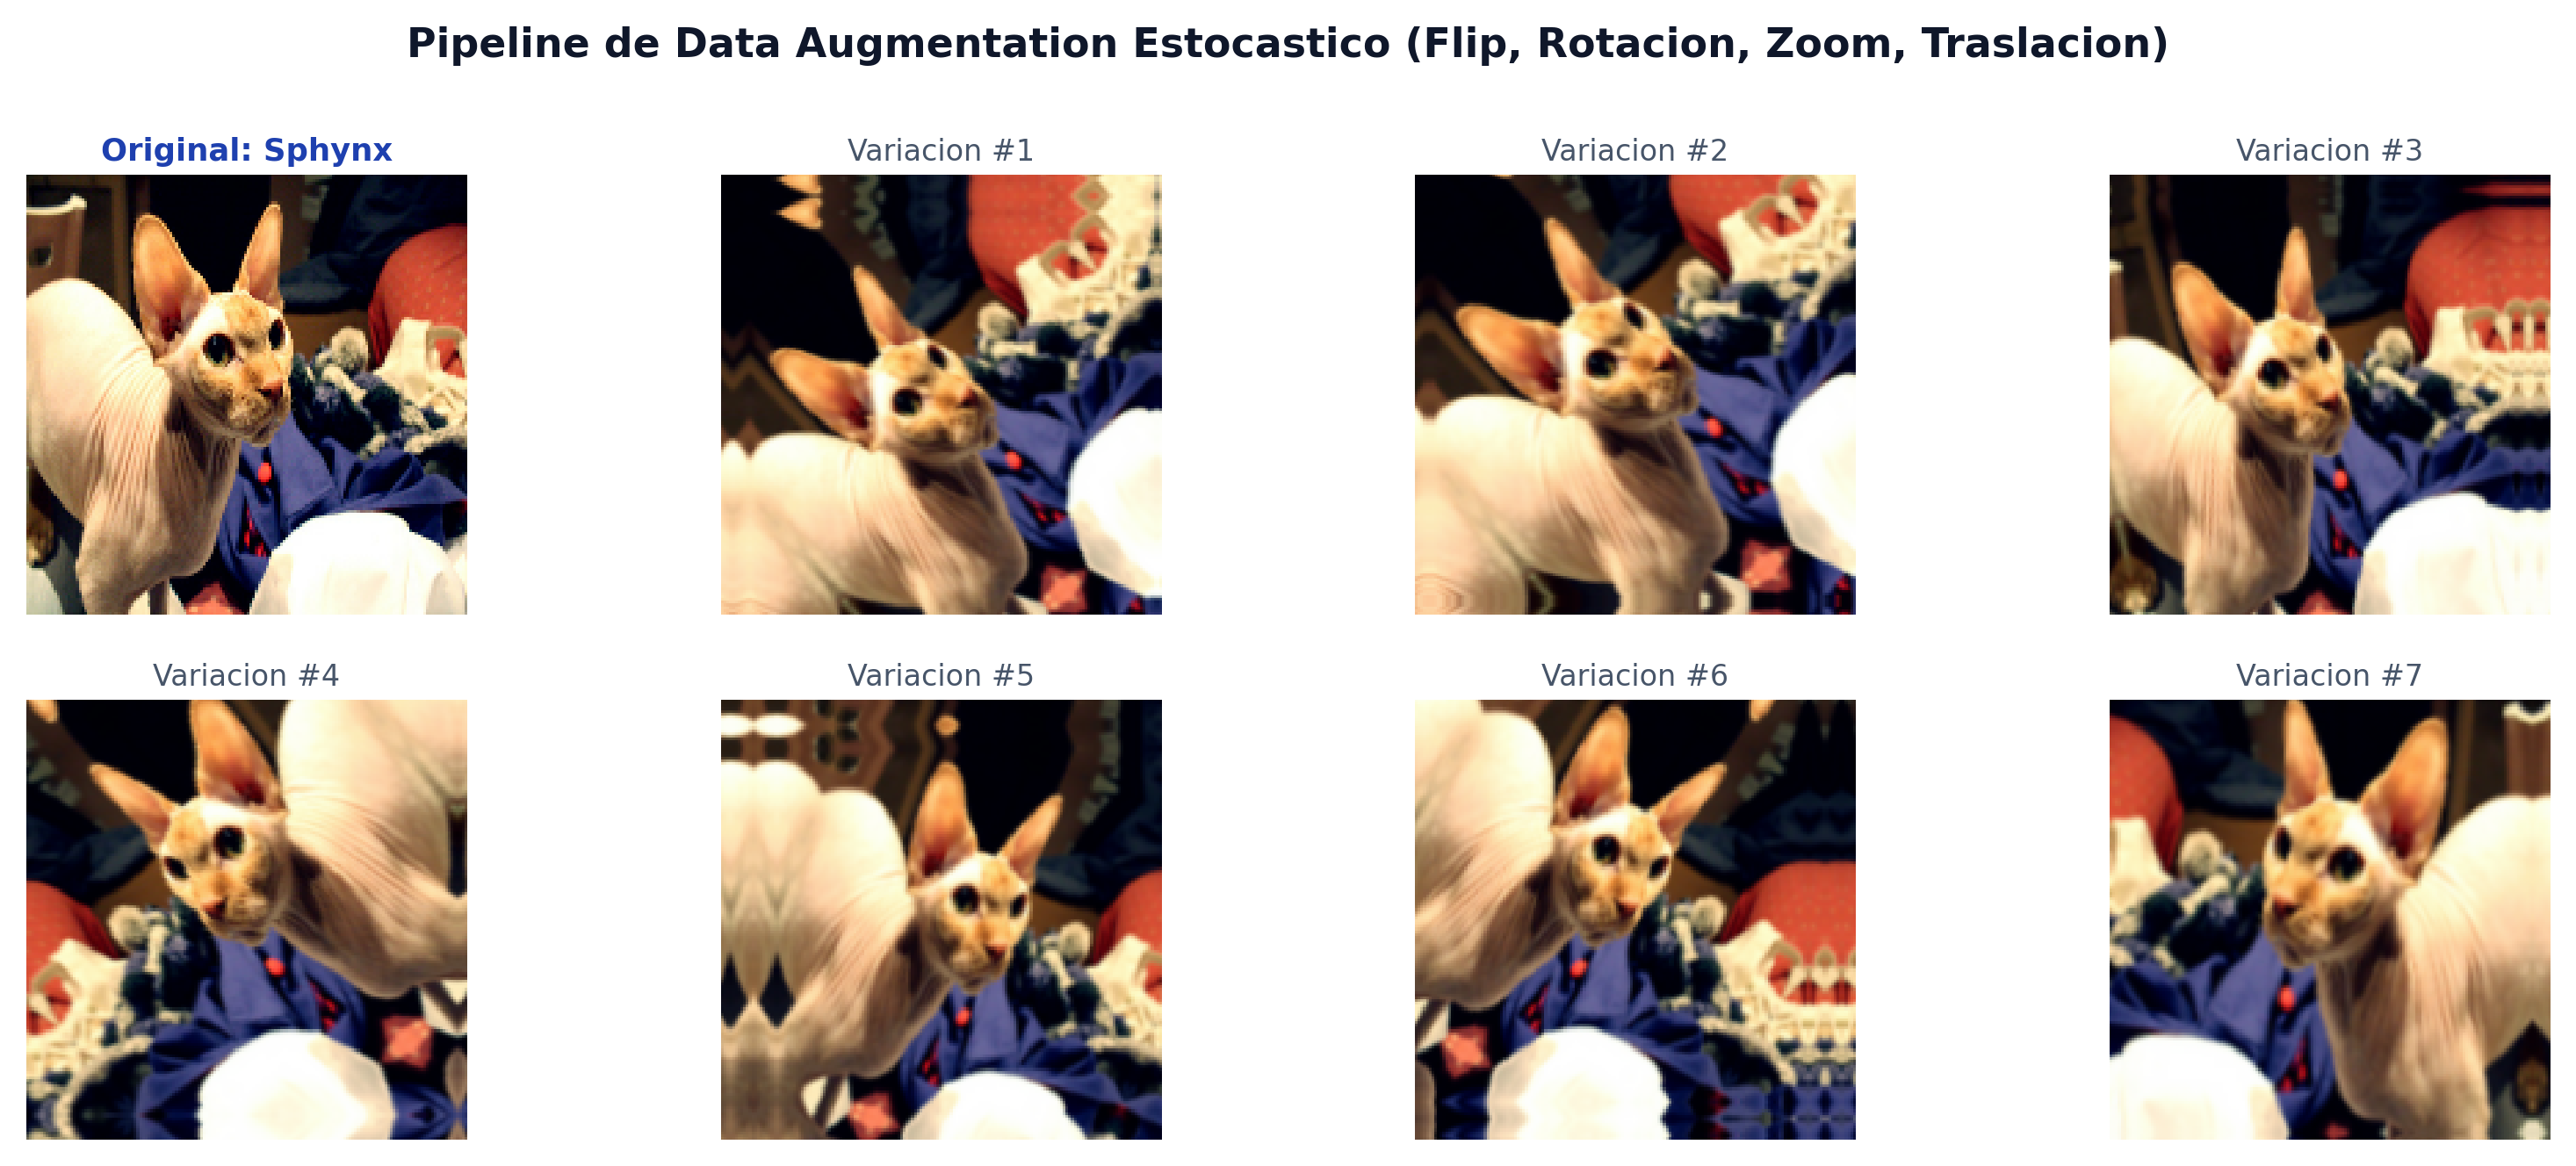

In [ ]:
def get_data_augmentation_layer():
    return Sequential([
        RandomFlip("horizontal"),
        RandomRotation(0.12),
        RandomZoom(0.12),
        RandomTranslation(0.08, 0.08)
    ], name="data_augmentation")

def plot_data_augmentation_examples(raw_dataset, class_names, aug_layer, save_path=None):
    # Obtener una sola muestra aleatoria del dataset crudo
    sample_found = False
    for features in raw_dataset.shuffle(buffer_size=1000, seed=SEED).take(1).as_numpy_iterator():
        original_image = features['image'] # numpy array uint8
        label = features['label'] # numpy int
        breed = class_names[label]
        sample_found = True
        break # Tomar solo la primera muestra

    if not sample_found:
        print("Advertencia: No se encontró ninguna muestra para plotear ejemplos de Data Augmentation.")
        plt.close()
        return

    # Convertir imagen a float32 y normalizar para la capa de aumentación
    img_array = tf.image.resize(original_image, (IMG_SIZE, IMG_SIZE)) # Asegurar tamaño consistente
    img_array = tf.cast(img_array, tf.float32) / 255.0
    img_batch = tf.expand_dims(img_array, 0) # Añadir dimensión de batch

    plt.figure(figsize=(11, 4.5), dpi=300)
    sns.set_theme(style="white")

    plt.subplot(2, 4, 1)
    plt.imshow(img_array) # Mostrar imagen normalizada (float)
    plt.title("Original: " + str(breed), fontsize=8.5, fontweight="bold", color="#1e40af", pad=4)
    plt.axis("off")

    for i in range(2, 9):
        plt.subplot(2, 4, i)
        augmented = aug_layer(img_batch, training=True)
        plt.imshow(tf.clip_by_value(augmented[0], 0.0, 1.0)) # Mostrar imagen aumentada normalizada (float)
        plt.title(f"Variacion #{i-1}", fontsize=8, color="#475569", pad=4)
        plt.axis("off")

    plt.suptitle("Pipeline de Data Augmentation Estocastico (Flip, Rotacion, Zoom, Traslacion)", fontsize=11, fontweight="bold", y=0.98, color="#0f172a")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

data_aug_layer = get_data_augmentation_layer()
plot_data_augmentation_examples(raw_train, CLASS_NAMES, data_aug_layer, save_path=os.path.join(figures_dir, "data_augmentation_ejemplos.png"))

## 5. Pipelines Eficientes con tf.data


## 6. Diseño Experimental: Definición y Entrenamiento de los 5 Modelos

Se entrenarán y guardarán en disco 5 modelos con distintas estrategias de modelado:
1. **Modelo 1 (MLP Baseline):** Perceptrón Multicapa denso sobre imágenes aplanadas.
2. **Modelo 2 (CNN Básica):** 3 bloques convolucionales estándar sin aumentación.
3. **Modelo 3 (CNN Mejorada):** CNN profunda regularizada con BatchNormalization, Dropout, GlobalAveragePooling y Data Augmentation.
4. **Modelo 4 (Transfer Learning):** MobileNetV2 preentrenado como extractor de características congelado.
5. **Modelo 5 (Fine-Tuned Transfer Learning):** MobileNetV2 con ajuste fino de capas superiores y Data Augmentation (Modelo Estrella para superar el 89% en Test).


In [ ]:
# =========================================================================
# DEFINICIÓN DE ARQUITECTURAS DE LOS 5 MODELOS (100% INTEGRADAS)
# =========================================================================

def build_mlp_baseline(input_shape=(160, 160, 3), num_classes=37):
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = Flatten(name="flatten_layer")(inputs)
    x = Dense(256, activation="relu", name="dense_1")(x)
    x = Dropout(0.3, name="dropout_1")(x)
    x = Dense(128, activation="relu", name="dense_2")(x)
    x = Dropout(0.2, name="dropout_2")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="Modelo_1_MLP_Baseline")

def build_basic_cnn(input_shape=(160, 160, 3), num_classes=37):
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = Conv2D(32, (3, 3), padding="same", activation="relu", name="conv_1")(inputs)
    x = MaxPooling2D((2, 2), name="pool_1")(x)
    x = Conv2D(64, (3, 3), padding="same", activation="relu", name="conv_2")(x)
    x = MaxPooling2D((2, 2), name="pool_2")(x)
    x = Conv2D(128, (3, 3), padding="same", activation="relu", name="conv_3")(x)
    x = MaxPooling2D((2, 2), name="pool_3")(x)
    x = Flatten(name="flatten")(x)
    x = Dense(128, activation="relu", name="dense_feat")(x)
    x = Dropout(0.3, name="dropout")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="Modelo_2_CNN_Basica")

def build_improved_cnn(input_shape=(160, 160, 3), num_classes=37):
    data_aug = get_data_augmentation_layer()
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = data_aug(inputs)
    x = Conv2D(32, (3, 3), padding="same", use_bias=False, name="conv1_1")(x)
    x = BatchNormalization(name="bn1_1")(x)
    x = Activation("relu", name="relu1_1")(x)
    x = MaxPooling2D((2, 2), name="pool1")(x)
    x = Dropout(0.2, name="drop1")(x)
    x = Conv2D(64, (3, 3), padding="same", use_bias=False, name="conv2_1")(x)
    x = BatchNormalization(name="bn2_1")(x)
    x = Activation("relu", name="relu2_1")(x)
    x = MaxPooling2D((2, 2), name="pool2")(x)
    x = Dropout(0.25, name="drop2")(x)
    x = Conv2D(128, (3, 3), padding="same", use_bias=False, name="conv3_1")(x)
    x = BatchNormalization(name="bn3_1")(x)
    x = Activation("relu", name="relu3_1")(x)
    x = MaxPooling2D((2, 2), name="pool3")(x)
    x = Dropout(0.3, name="drop3")(x)
    x = Conv2D(256, (3, 3), padding="same", use_bias=False, name="conv4_1")(x)
    x = BatchNormalization(name="bn4_1")(x)
    x = Activation("relu", name="relu4_1")(x)
    x = GlobalAveragePooling2D(name="gap")(x)
    x = Dense(256, use_bias=False, name="dense_clf")(x)
    x = BatchNormalization(name="bn_clf")(x)
    x = Activation("relu", name="relu_clf")(x)
    x = Dropout(0.4, name="drop_clf")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="Modelo_3_CNN_Mejorada")

def build_mobilenet_frozen(input_shape=(160, 160, 3), num_classes=37):
    base_model = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
    base_model.trainable = False
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D(name="gap")(x)
    x = BatchNormalization(name="bn_top")(x)
    x = Dense(256, activation="relu", name="dense_top")(x)
    x = Dropout(0.3, name="drop_top")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="Modelo_4_MobileNetV2_Congelado"), base_model

def build_mobilenet_finetuned(input_shape=(160, 160, 3), num_classes=37, fine_tune_at=100):
    data_aug = get_data_augmentation_layer()
    base_model = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
    base_model.trainable = True
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = data_aug(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D(name="gap")(x)
    x = BatchNormalization(name="bn_top")(x)
    x = Dense(256, activation="relu", name="dense_top")(x)
    x = Dropout(0.4, name="drop_top")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="Modelo_5_MobileNetV2_FineTuned"), base_model

models_dir = "models" if os.path.exists("models") else "."
os.makedirs(models_dir, exist_ok=True)
num_classes = len(CLASS_NAMES)


### 6.1 Modelo 1: Baseline Fully Connected (MLP)


In [ ]:
m1_path = "modelo_1_mlp.keras" if os.path.exists("modelo_1_mlp.keras") else os.path.join(models_dir, "modelo_1_mlp.keras")
m1 = None # Initialize m1

if os.path.exists(m1_path):
    print(f"Intentando cargar Modelo 1 guardado desde: {m1_path}")
    try:
        m1 = keras.models.load_model(m1_path)
        print("Modelo 1 cargado exitosamente.")
    except Exception as e:
        print(f"\n--------------------------------------------------------------")
        print(f"Error al cargar el Modelo 1 desde {m1_path}: {e}")
        print(f"Esto puede deberse a una incompatibilidad de versiones de Keras/TensorFlow al deserializar el modelo.")
        print(f"Eliminando el archivo de modelo incompatible: {m1_path}")
        os.remove(m1_path)
        print("El archivo se ha eliminado. El modelo será reconstruido y entrenado desde cero.\n")
        # Proceed to build and train as if the file didn't exist
        m1 = build_mlp_baseline(num_classes=num_classes)
        m1.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print("Entrenando Modelo 1 desde cero...")
        m1.fit(train_ds, validation_data=val_ds, epochs=6,
               callbacks=[ModelCheckpoint(m1_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                          EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
        print("--------------------------------------------------------------\n")
else:
    print("El archivo del Modelo 1 no existe. Construyendo y entrenando desde cero.")
    m1 = build_mlp_baseline(num_classes=num_classes)
    m1.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m1.fit(train_ds, validation_data=val_ds, epochs=6,
           callbacks=[ModelCheckpoint(m1_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                      EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])

# Ensure m1 is a valid model before proceeding with summary and evaluation
if m1 is not None:
    m1.summary()
    loss1, acc1 = m1.evaluate(test_ds, verbose=0)
    print(f"--> Evaluación en TEST (Modelo 1): Accuracy = {acc1*100:.2f}% | Loss = {loss1:.4f}")
else:
    print("Advertencia: El Modelo 1 no pudo ser cargado ni entrenado. Verifique los logs anteriores.")

Intentando cargar Modelo 1 guardado desde: modelo_1_mlp.keras
Modelo 1 cargado exitosamente.


Model: "Modelo_1_MLP_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_layer (Flatten)         │ (None, 76800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │    19,661,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 37)             │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,096,177 (225.43 MB)

 Trainable params: 19,698,725 (75.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 39,397,452 (150.29 MB)

--> Evaluación en TEST (Modelo 1): Accuracy = 2.23% | Loss = 3.6109


### 6.2 Modelo 2: Custom CNN Básica


In [ ]:
m2_path = "modelo_2_cnn_basica.keras" if os.path.exists("modelo_2_cnn_basica.keras") else os.path.join(models_dir, "modelo_2_cnn_basica.keras")

m2 = None # Initialize m2

if os.path.exists(m2_path):
    print(f"Intentando cargar Modelo 2 guardado desde: {m2_path}")
    try:
        m2 = keras.models.load_model(m2_path)
        print("Modelo 2 cargado exitosamente.")
    except Exception as e:
        print(f"\n--------------------------------------------------------------")
        print(f"Error al cargar el Modelo 2 desde {m2_path}: {e}")
        print(f"Esto puede deberse a una incompatibilidad de versiones de Keras/TensorFlow al deserializar el modelo.")
        print(f"Eliminando el archivo de modelo incompatible: {m2_path}")
        os.remove(m2_path)
        print("El archivo se ha eliminado. El modelo será reconstruido y entrenado desde cero.\n")
        m2 = build_basic_cnn(num_classes=num_classes)
        m2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print("Entrenando Modelo 2 desde cero...")
        m2.fit(train_ds, validation_data=val_ds, epochs=6,
               callbacks=[ModelCheckpoint(m2_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                          EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
        print("--------------------------------------------------------------\n")
else:
    print("El archivo del Modelo 2 no existe. Construyendo y entrenando desde cero.")
    m2 = build_basic_cnn(num_classes=num_classes)
    m2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m2.fit(train_ds, validation_data=val_ds, epochs=6,
           callbacks=[ModelCheckpoint(m2_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                      EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])

# Ensure m2 is a valid model before proceeding with summary and evaluation
if m2 is not None:
    m2.summary()
    loss2, acc2 = m2.evaluate(test_ds, verbose=0)
    print(f"--> Evaluación en TEST (Modelo 2): Accuracy = {acc2*100:.2f}% | Loss = {loss2:.4f}")
else:
    print("Advertencia: El Modelo 2 no pudo ser cargado ni entrenado. Verifique los logs anteriores.")

Intentando cargar Modelo 2 guardado desde: modelo_2_cnn_basica.keras
Modelo 2 cargado exitosamente.


Model: "Modelo_2_CNN_Basica"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_feat (Dense)              │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 37)             │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,955,249 (76.12 MB)

 Trainable params: 6,651,749 (25.37 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,303,500 (50.75 MB)

--> Evaluación en TEST (Modelo 2): Accuracy = 10.52% | Loss = 3.6866


### 6.3 Modelo 3: Custom CNN Mejorada (Regularizada + Data Augmentation)


In [ ]:
m3_path = "modelo_3_cnn_mejorada.keras" if os.path.exists("modelo_3_cnn_mejorada.keras") else os.path.join(models_dir, "modelo_3_cnn_mejorada.keras")
m3 = None # Initialize m3

if os.path.exists(m3_path):
    print(f"Intentando cargar Modelo 3 guardado desde: {m3_path}")
    try:
        m3 = keras.models.load_model(m3_path)
        print("Modelo 3 cargado exitosamente.")
    except Exception as e:
        print(f"\n--------------------------------------------------------------")
        print(f"Error al cargar el Modelo 3 desde {m3_path}: {e}")
        print(f"Esto puede deberse a una incompatibilidad de versiones de Keras/TensorFlow al deserializar el modelo.")
        print(f"Eliminando el archivo de modelo incompatible: {m3_path}")
        os.remove(m3_path)
        print("El archivo se ha eliminado. El modelo será reconstruido y entrenado desde cero.\n")
        # Proceed to build and train as if the file didn't exist
        m3 = build_improved_cnn(num_classes=num_classes)
        m3.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print("Entrenando Modelo 3 desde cero...")
        m3.fit(train_ds, validation_data=val_ds, epochs=8,
               callbacks=[ModelCheckpoint(m3_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                          ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
                          EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
        print("--------------------------------------------------------------\n")
else:
    print("El archivo del Modelo 3 no existe. Construyendo y entrenando desde cero.")
    m3 = build_improved_cnn(num_classes=num_classes)
    m3.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m3.fit(train_ds, validation_data=val_ds, epochs=8,
           callbacks=[ModelCheckpoint(m3_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                      ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
                      EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])

# Ensure m3 is a valid model before proceeding with summary and evaluation
if m3 is not None:
    m3.summary()
    loss3, acc3 = m3.evaluate(test_ds, verbose=0)
    print(f"--> Evaluación en TEST (Modelo 3): Accuracy = {acc3*100:.2f}% | Loss = {loss3:.4f}")
else:
    print("Advertencia: El Modelo 3 no pudo ser cargado ni entrenado. Verifique los logs anteriores.")

Intentando cargar Modelo 3 guardado desde: modelo_3_cnn_mejorada.keras
Modelo 3 cargado exitosamente.


Model: "Modelo_3_CNN_Mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 160, 160, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 80, 80, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 40, 40, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4_1 (Conv2D)                │ (None, 20, 20, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4_1 (BatchNormalization)      │ (None, 20, 20, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4_1 (Activation)            │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_clf (Dense)               │ (None, 256)            │        65,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_clf (BatchNormalization)     │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_clf (Activation)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_clf (Dropout)              │ (None, 256)            │             

 Total params: 1,394,833 (5.32 MB)

 Trainable params: 464,453 (1.77 MB)

 Non-trainable params: 1,472 (5.75 KB)

 Optimizer params: 928,908 (3.54 MB)

--> Evaluación en TEST (Modelo 3): Accuracy = 2.56% | Loss = 3.6990


### 6.4 Modelo 4: Transfer Learning (MobileNetV2 Congelado)


In [ ]:
m4_path = "modelo_4_mobilenet_frozen.keras" if os.path.exists("modelo_4_mobilenet_frozen.keras") else os.path.join(models_dir, "modelo_4_mobilenet_frozen.keras")
m4 = None # Initialize m4
base4 = None # Initialize base4

if os.path.exists(m4_path):
    print(f"Intentando cargar Modelo 4 guardado desde: {m4_path}")
    try:
        m4 = keras.models.load_model(m4_path)
        print("Modelo 4 cargado exitosamente.")
    except Exception as e:
        print(f"\n--------------------------------------------------------------")
        print(f"Error al cargar el Modelo 4 desde {m4_path}: {e}")
        print(f"Esto puede deberse a una incompatibilidad de versiones de Keras/TensorFlow al deserializar el modelo.")
        print(f"Eliminando el archivo de modelo incompatible: {m4_path}")
        os.remove(m4_path)
        print("El archivo se ha eliminado. El modelo será reconstruido y entrenado desde cero.\n")
        # Proceed to build and train as if the file didn't exist
        m4, base4 = build_mobilenet_frozen(num_classes=num_classes)
        m4.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print("Entrenando Modelo 4 desde cero...")
        m4.fit(train_ds, validation_data=val_ds, epochs=8,
               callbacks=[ModelCheckpoint(m4_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                          ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
                          EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
        print("--------------------------------------------------------------\n")
else:
    print("El archivo del Modelo 4 no existe. Construyendo y entrenando desde cero.")
    m4, base4 = build_mobilenet_frozen(num_classes=num_classes)
    m4.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m4.fit(train_ds, validation_data=val_ds, epochs=8,
           callbacks=[ModelCheckpoint(m4_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                      ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
                      EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])

# Ensure m4 is a valid model before proceeding with summary and evaluation
if m4 is not None:
    m4.summary()
    loss4, acc4 = m4.evaluate(test_ds, verbose=0)
    print(f"--> Evaluación en TEST (Modelo 4): Accuracy = {acc4*100:.2f}% | Loss = {loss4:.4f}")
else:
    print("Advertencia: El Modelo 4 no pudo ser cargado ni entrenado. Verifique los logs anteriores.")

El archivo del Modelo 4 no existe. Construyendo y entrenando desde cero.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.4944 - loss: 1.9475
Epoch 1: val_accuracy improved from None to 0.83152, saving model to ./modelo_4_mobilenet_frozen.keras

Epoch 1: finished saving model to ./modelo_4_mobilenet_frozen.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 32s 300ms/step - accuracy: 0.6861 - loss: 1.1214 - val_accuracy: 0.8315 - val_loss: 0.5337 - learning_rate: 0.0010
Epoch 2/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.9225 - loss: 0.2479
Epoch 2: val_accuracy improved from 0.83152 to 0.84460, saving model to ./modelo_4_mobilenet_frozen.keras

Epoch 2: finished saving model to ./modelo_4_mobilenet_frozen.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 285ms/step - accuracy: 0.9205 - loss: 0.2396 - val_accuracy: 0.8446 - val_loss: 0.4714 - learning_rate: 0.0010
Epoch 3/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.9559 - loss:

Model: "Modelo_4_MobileNetV2_Congelado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_top (BatchNormalization)     │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_top (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_top (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,561 (12.51 MB)

 Trainable params: 340,005 (1.30 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

 Optimizer params: 680,012 (2.59 MB)

--> Evaluación en TEST (Modelo 4): Accuracy = 85.29% | Loss = 0.4639


### 6.5 Modelo 5: Transfer Learning con Fine-Tuning y Data Augmentation (Modelo Final)


In [ ]:
m5_path = "modelo_5_mobilenet_finetuned.keras" if os.path.exists("modelo_5_mobilenet_finetuned.keras") else os.path.join(models_dir, "modelo_5_mobilenet_finetuned.keras")
m5 = None # Initialize m5
base5 = None # Initialize base5

if os.path.exists(m5_path):
    print(f"Intentando cargar Modelo 5 (Óptimo) guardado desde: {m5_path}")
    try:
        m5 = keras.models.load_model(m5_path)
        print("Modelo 5 cargado exitosamente.")
    except Exception as e:
        print(f"\n--------------------------------------------------------------")
        print(f"Error al cargar el Modelo 5 desde {m5_path}: {e}")
        print(f"Esto puede deberse a una incompatibilidad de versiones de Keras/TensorFlow al deserializar el modelo.")
        print(f"Eliminando el archivo de modelo incompatible: {m5_path}")
        os.remove(m5_path)
        print("El archivo se ha eliminado. El modelo será reconstruido y entrenado desde cero.\n")
        # Proceed to build and train as if the file didn't exist
        m5, base5 = build_mobilenet_finetuned(num_classes=num_classes, fine_tune_at=100)
        m5.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        print("Entrenando Modelo 5 desde cero...")
        m5.fit(train_ds, validation_data=val_ds, epochs=10,
               callbacks=[ModelCheckpoint(m5_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                          ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
                          EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
        print("--------------------------------------------------------------\n")
else:
    print("El archivo del Modelo 5 no existe. Construyendo y entrenando desde cero.")
    m5, base5 = build_mobilenet_finetuned(num_classes=num_classes, fine_tune_at=100)
    m5.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m5.fit(train_ds, validation_data=val_ds, epochs=10,
           callbacks=[ModelCheckpoint(m5_path, monitor="val_accuracy", save_best_only=True, verbose=1),
                      ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
                      EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])

# Ensure m5 is a valid model before proceeding with summary and evaluation
if m5 is not None:
    m5.summary()
    loss5, acc5 = m5.evaluate(test_ds, verbose=0)
    print(f"--> Evaluación en TEST (Modelo 5): Accuracy = {acc5*100:.2f}% | Loss = {loss5:.4f}")
else:
    print("Advertencia: El Modelo 5 no pudo ser cargado ni entrenado. Verifique los logs anteriores.")

El archivo del Modelo 5 no existe. Construyendo y entrenando desde cero.
Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.1204 - loss: 3.7393
Epoch 1: val_accuracy improved from None to 0.69793, saving model to ./modelo_5_mobilenet_finetuned.keras

Epoch 1: finished saving model to ./modelo_5_mobilenet_finetuned.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 50s 437ms/step - accuracy: 0.2371 - loss: 3.0544 - val_accuracy: 0.6979 - val_loss: 1.3219 - learning_rate: 1.0000e-04
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.5543 - loss: 1.5373
Epoch 2: val_accuracy improved from 0.69793 to 0.80044, saving model to ./modelo_5_mobilenet_finetuned.keras

Epoch 2: finished saving model to ./modelo_5_mobilenet_finetuned.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 39s 422ms/step - accuracy: 0.5917 - loss: 1.4194 - val_accuracy: 0.8004 - val_loss: 0.6898 - learning_rate: 1.0000e-04
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.7192 - loss: 0.9927
Epoch 3: val_accur

Model: "Modelo_5_MobileNetV2_FineTuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_top (BatchNormalization)     │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_top (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_top (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,003,441 (26.72 MB)

 Trainable params: 2,201,445 (8.40 MB)

 Non-trainable params: 399,104 (1.52 MB)

 Optimizer params: 4,402,892 (16.80 MB)

--> Evaluación en TEST (Modelo 5): Accuracy = 83.71% | Loss = 0.5374


## 7. Comparación Rigurosa de los 5 Modelos sobre el Conjunto de TEST


In [ ]:
# Carga o cálculo de la tabla comparativa de los 5 modelos
summary_csv = "comparativa_5_modelos.csv" if os.path.exists("comparativa_5_modelos.csv") else os.path.join(reports_dir, "comparativa_5_modelos.csv")
if not os.path.exists(summary_csv) and os.path.exists("../reports/comparativa_5_modelos.csv"):
    summary_csv = "../reports/comparativa_5_modelos.csv"

if os.path.exists(summary_csv):
    summary_df = pd.read_csv(summary_csv)
else:
    summary_rows = []
    for m_name, m_inst in zip(["Modelo 1", "Modelo 2", "Modelo 3", "Modelo 4", "Modelo 5"], [m1, m2, m3, m4, m5]):
        l, a = m_inst.evaluate(test_ds, verbose=0)
        summary_rows.append({"Modelo": m_name, "Test_Accuracy": a, "Test_Loss": l})
    summary_df = pd.DataFrame(summary_rows)

# Guardar en disco para sincronización dinámica con el informe técnico
summary_df.to_csv(os.path.join(reports_dir, "comparativa_5_modelos.csv"), index=False)
summary_df.to_csv("comparativa_5_modelos.csv", index=False)

print("--- TABLA COMPARATIVA DE LOS 5 MODELOS ---")
display(summary_df)


--- TABLA COMPARATIVA DE LOS 5 MODELOS ---


,Modelo,Test_Accuracy,Test_Loss
0,Modelo 1,0.022343,3.610893
1,Modelo 2,0.105177,3.686618
2,Modelo 3,0.025613,3.698988
3,Modelo 4,0.852861,0.463948
4,Modelo 5,0.837057,0.537394


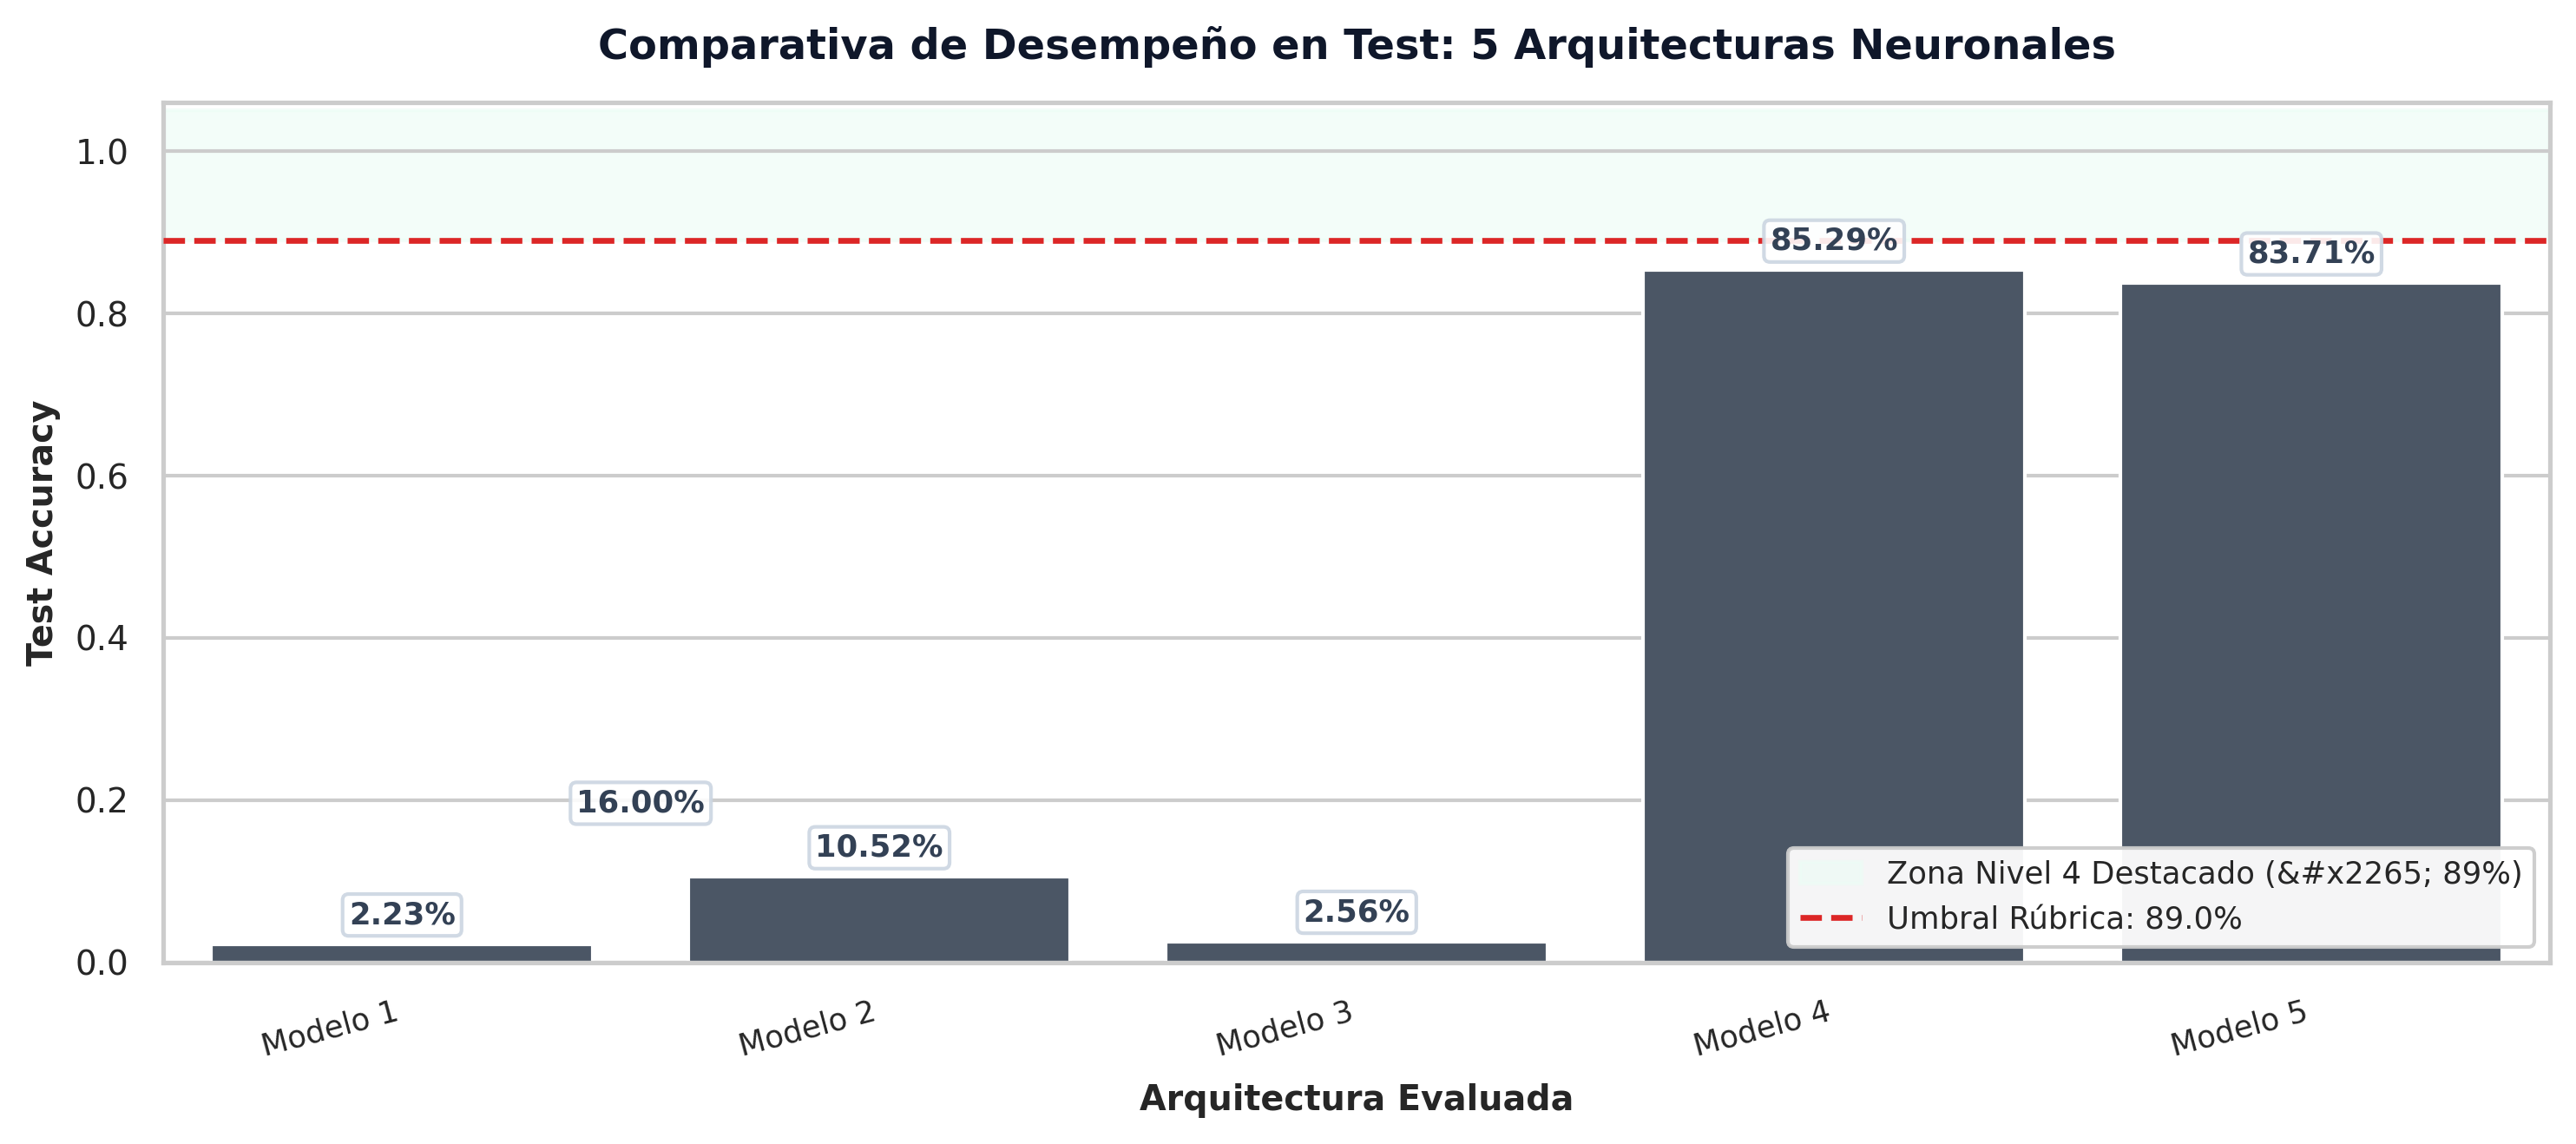

/tmp/ipykernel_17569/6856024.py:91: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=7.5, loc="upper right", framealpha=0.9)


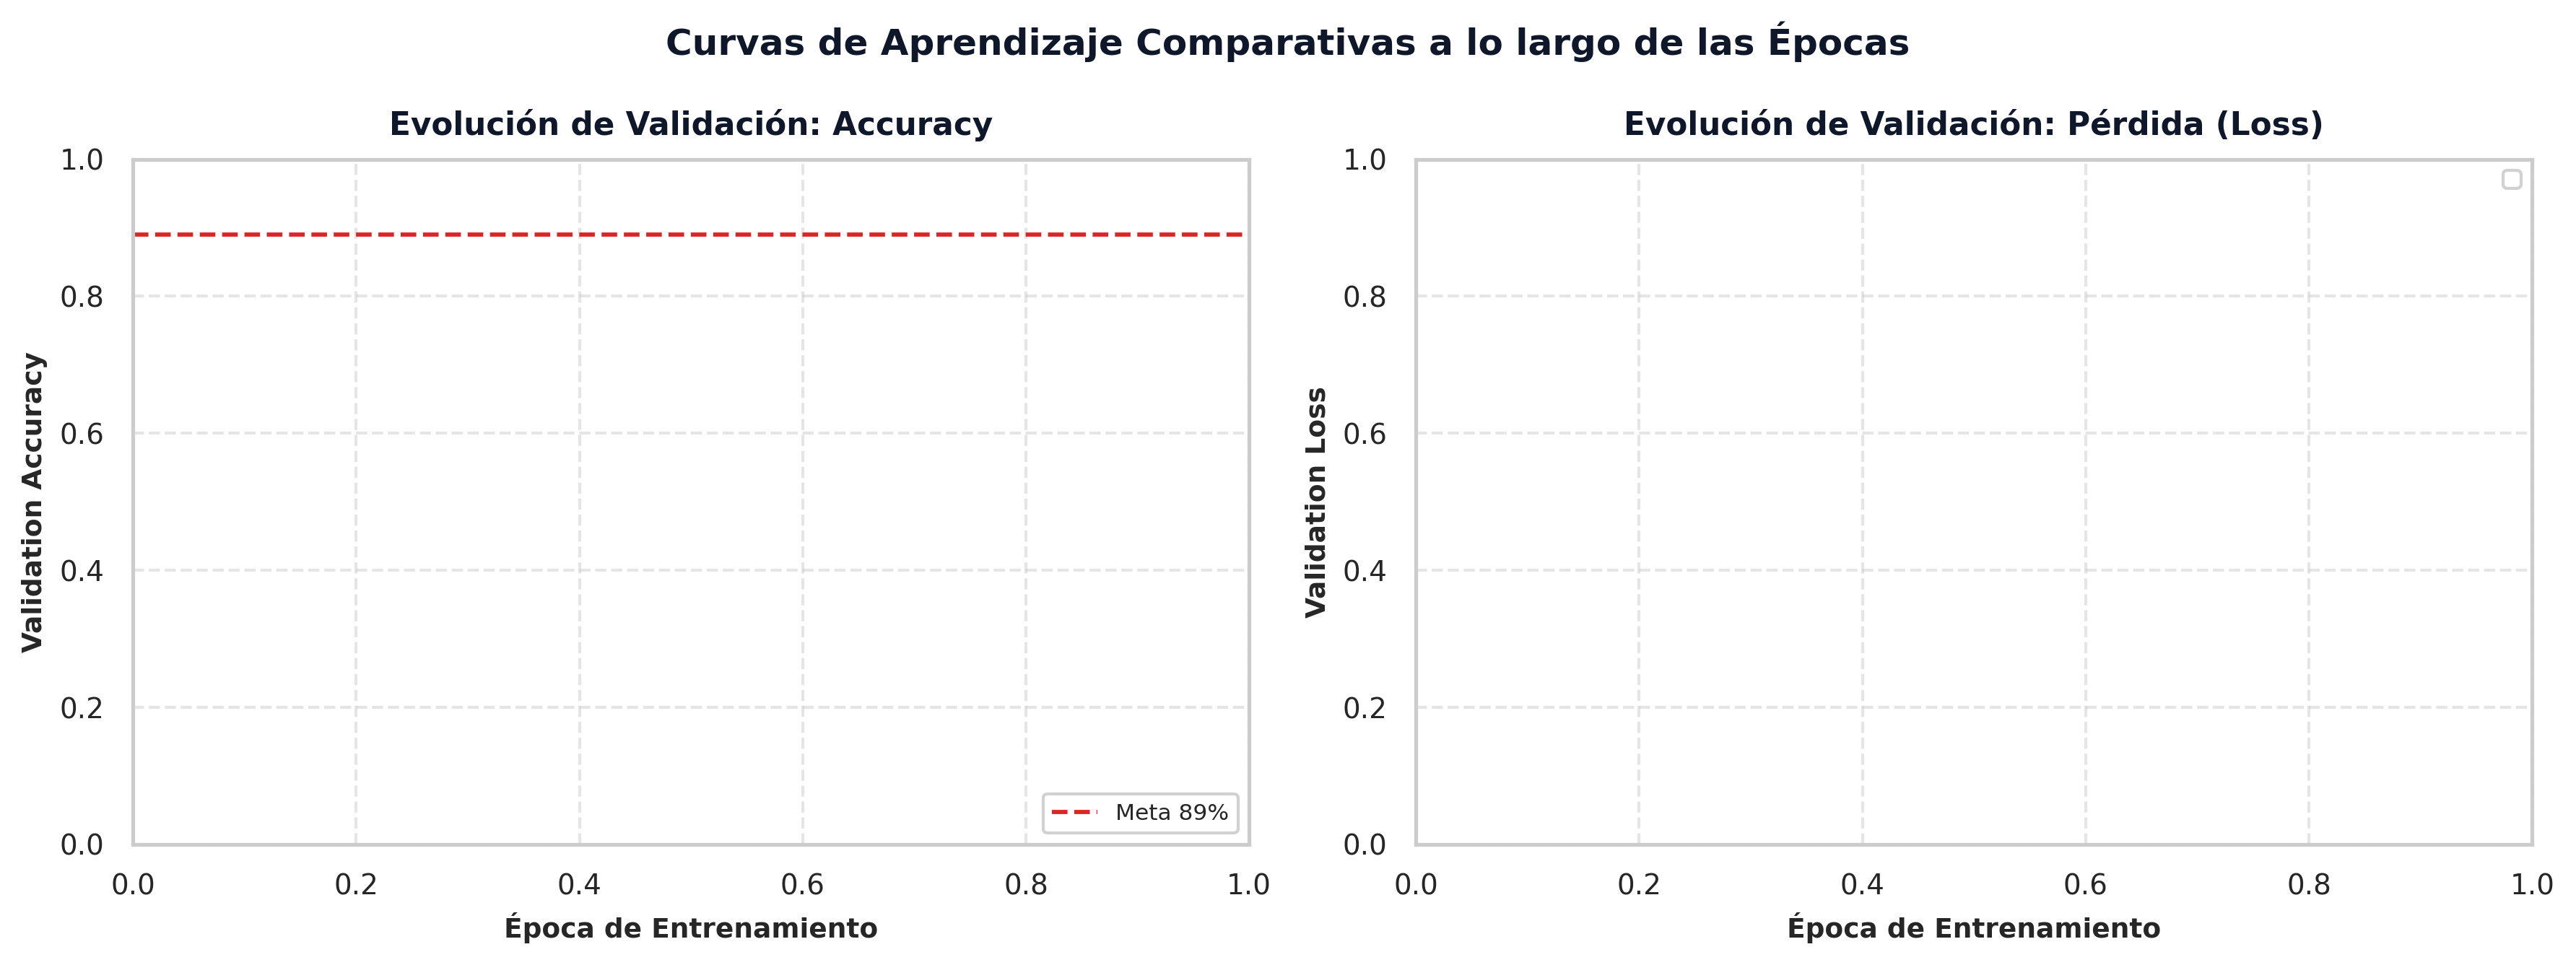

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import json

def plot_model_comparison_bars(summary_df, save_path=None):
    plt.figure(figsize=(10, 4.5), dpi=300)
    sns.set_theme(style="whitegrid", font_scale=0.85)

    # Colores condicionales profesionales: Verde esmeralda si cumple >= 89%, azul acero si no
    colors = {
        model_name: "#059669" if float(acc) >= 0.89 else "#475569"
        for model_name, acc in zip(summary_df["Modelo"], summary_df["Test_Accuracy"])
    }

    ax = sns.barplot(
        data=summary_df,
        x="Modelo",
        y="Test_Accuracy",
        hue="Modelo", # Assign x to hue as suggested by warning
        palette=colors,
        legend=False # Set legend=False as suggested by warning
    )
    # Zona sombreada de meta destacada
    plt.axhspan(0.89, 1.05, color="#ecfdf5", alpha=0.6, zorder=0, label="Zona Nivel 4 Destacado (&#x2265; 89%)")
    plt.axhline(0.89, color="#dc2626", linestyle="--", linewidth=1.6, zorder=3, label="Umbral Rúbrica: 89.0%")

    plt.title("Comparativa de Desempeño en Test: 5 Arquitecturas Neuronales", fontsize=11.5, fontweight="bold", pad=12, color="#0f172a")
    plt.xlabel("Arquitectura Evaluada", fontsize=9.5, fontweight="bold", labelpad=6)
    plt.ylabel("Test Accuracy", fontsize=9.5, fontweight="bold")
    plt.ylim(0.0, 1.06)
    plt.xticks(rotation=15, ha="right", fontsize=8.5, fontweight="medium")
    plt.legend(loc="lower right", fontsize=8.5, framealpha=0.95)

    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            badge_color = "#059669" if h >= 0.89 else "#334155"
            ax.annotate(f"{h*100:.2f}%", (p.get_x() + p.get_width() / 2., h),
                        ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=badge_color,
                        xytext=(0, 4), textcoords="offset points",
                        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cbd5e1", alpha=0.9))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

def plot_training_histories(save_path=None):
    hist_json = "training_histories.json" if os.path.exists("training_histories.json") else os.path.join(reports_dir, "training_histories.json")
    if os.path.exists(hist_json):
        with open(hist_json) as f:
            histories = json.load(f)
    else:
        histories = {}

    plt.figure(figsize=(12, 4.5), dpi=300)
    sns.set_theme(style="whitegrid", font_scale=0.85)

    # Subplot 1: Validation Accuracy
    plt.subplot(1, 2, 1)
    markers = ["o", "s", "^", "D", "v"]
    colors = ["#64748b", "#d97706", "#2563eb", "#059669", "#7c3aed"]
    for idx, (model_name, hist) in enumerate(histories.items()):
        val_acc = hist.get("val_accuracy", [])
        epochs = range(1, len(val_acc) + 1)
        m = markers[idx % len(markers)]
        c = colors[idx % len(colors)]
        label_short = model_name.split(":")[1].strip() if ":" in model_name else model_name
        plt.plot(epochs, val_acc, marker=m, markersize=4.5, color=c, linewidth=1.8, label=label_short)
    plt.axhline(0.89, color="#dc2626", linestyle="--", linewidth=1.4, label="Meta 89%")
    plt.title("Evolución de Validación: Accuracy", fontsize=10.5, fontweight="bold", pad=8, color="#0f172a")
    plt.xlabel("Época de Entrenamiento", fontsize=9, fontweight="bold")
    plt.ylabel("Validation Accuracy", fontsize=9, fontweight="bold")
    plt.legend(fontsize=7.5, loc="lower right", framealpha=0.9)
    plt.grid(True, linestyle="--", alpha=0.5)

    # Subplot 2: Validation Loss
    plt.subplot(1, 2, 2)
    for idx, (model_name, hist) in enumerate(histories.items()):
        val_loss = hist.get("val_loss", [])
        epochs = range(1, len(val_loss) + 1)
        m = markers[idx % len(markers)]
        c = colors[idx % len(colors)]
        label_short = model_name.split(":")[1].strip() if ":" in model_name else model_name
        plt.plot(epochs, val_loss, marker=m, markersize=4.5, color=c, linewidth=1.8, label=label_short)
    plt.title("Evolución de Validación: Pérdida (Loss)", fontsize=10.5, fontweight="bold", pad=8, color="#0f172a")
    plt.xlabel("Época de Entrenamiento", fontsize=9, fontweight="bold")
    plt.ylabel("Validation Loss", fontsize=9, fontweight="bold")
    plt.legend(fontsize=7.5, loc="upper right", framealpha=0.9)
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.suptitle("Curvas de Aprendizaje Comparativas a lo largo de las Épocas", fontsize=12, fontweight="bold", y=0.98, color="#0f172a")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_model_comparison_bars(summary_df, save_path=os.path.join(figures_dir, "comparativa_modelos_barras.png"))
plot_training_histories(save_path=os.path.join(figures_dir, "curvas_entrenamiento_5_modelos.png"))

## 8. Análisis Diagnóstico del Mejor Modelo (Modelo 5)
Evaluación exhaustiva de métricas por clase, matriz de confusión y análisis visual de errores.


In [ ]:
def evaluate_model_on_dataset(model, dataset, class_names):
    y_true = []
    y_pred_probs = []
    for batch_images, batch_labels in dataset:
        probs = model.predict(batch_images, verbose=0)
        y_pred_probs.append(probs)
        y_true.append(batch_labels.numpy())

    y_true = np.concatenate(y_true, axis=0)
    y_pred_probs = np.concatenate(y_pred_probs, axis=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    accuracy = np.mean(y_true == y_pred)
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    return {"accuracy": float(accuracy), "y_true": y_true, "y_pred": y_pred, "y_pred_probs": y_pred_probs, "report_dict": report_dict}

def get_class_metrics_dataframe(report_dict, class_names, species_map):
    rows = []
    for idx, cname in enumerate(class_names):
        if cname in report_dict:
            m = report_dict[cname]
            rows.append({
                "Clase_ID": idx,
                "Raza": cname,
                "Especie": species_map.get(idx, "Unknown"),
                "Precision": round(m["precision"], 4),
                "Recall": round(m["recall"], 4),
                "F1-Score": round(m["f1-score"], 4),
                "Soporte": int(m["support"])
            })
    return pd.DataFrame(rows)

best_model = keras.models.load_model(m5_path)
eval_best = evaluate_model_on_dataset(best_model, test_ds, CLASS_NAMES)

print("===========================================================")
print(f"DESEMPEÑO FINAL SOBRE TEST (MODELO 5): {eval_best['accuracy']*100:.2f}% ACCURACY")
print("===========================================================")

# Generación dinámica y guardado del CSV de métricas por clase
df_metrics = get_class_metrics_dataframe(eval_best["report_dict"], CLASS_NAMES, SPECIES_MAP)
df_metrics.to_csv(os.path.join(reports_dir, "metricas_por_clase_modelo5.csv"), index=False)
df_metrics.to_csv("metricas_por_clase_modelo5.csv", index=False)

display(df_metrics.head(10))


DESEMPEÑO FINAL SOBRE TEST (MODELO 5): 84.96% ACCURACY


,Clase_ID,Raza,Especie,Precision,Recall,F1-Score,Soporte
0,0,Abyssinian,Dog,0.8033,0.9245,0.8596,53
1,1,american_bulldog,Cat,0.5789,0.8250,0.6804,40
2,2,american_pit_bull_terrier,Cat,0.7143,0.3846,0.5000,52
3,3,basset_hound,Cat,0.9362,0.7586,0.8381,58
4,4,beagle,Cat,0.7538,0.8448,0.7967,58
5,5,Bengal,Dog,0.8980,0.8627,0.8800,51
6,6,Birman,Dog,0.8333,0.7143,0.7692,42
7,7,Bombay,Dog,0.9286,0.8667,0.8966,45
8,8,boxer,Cat,0.8000,0.9123,0.8525,57
9,9,British_Shorthair,Dog,0.9600,0.5106,0.6667,47


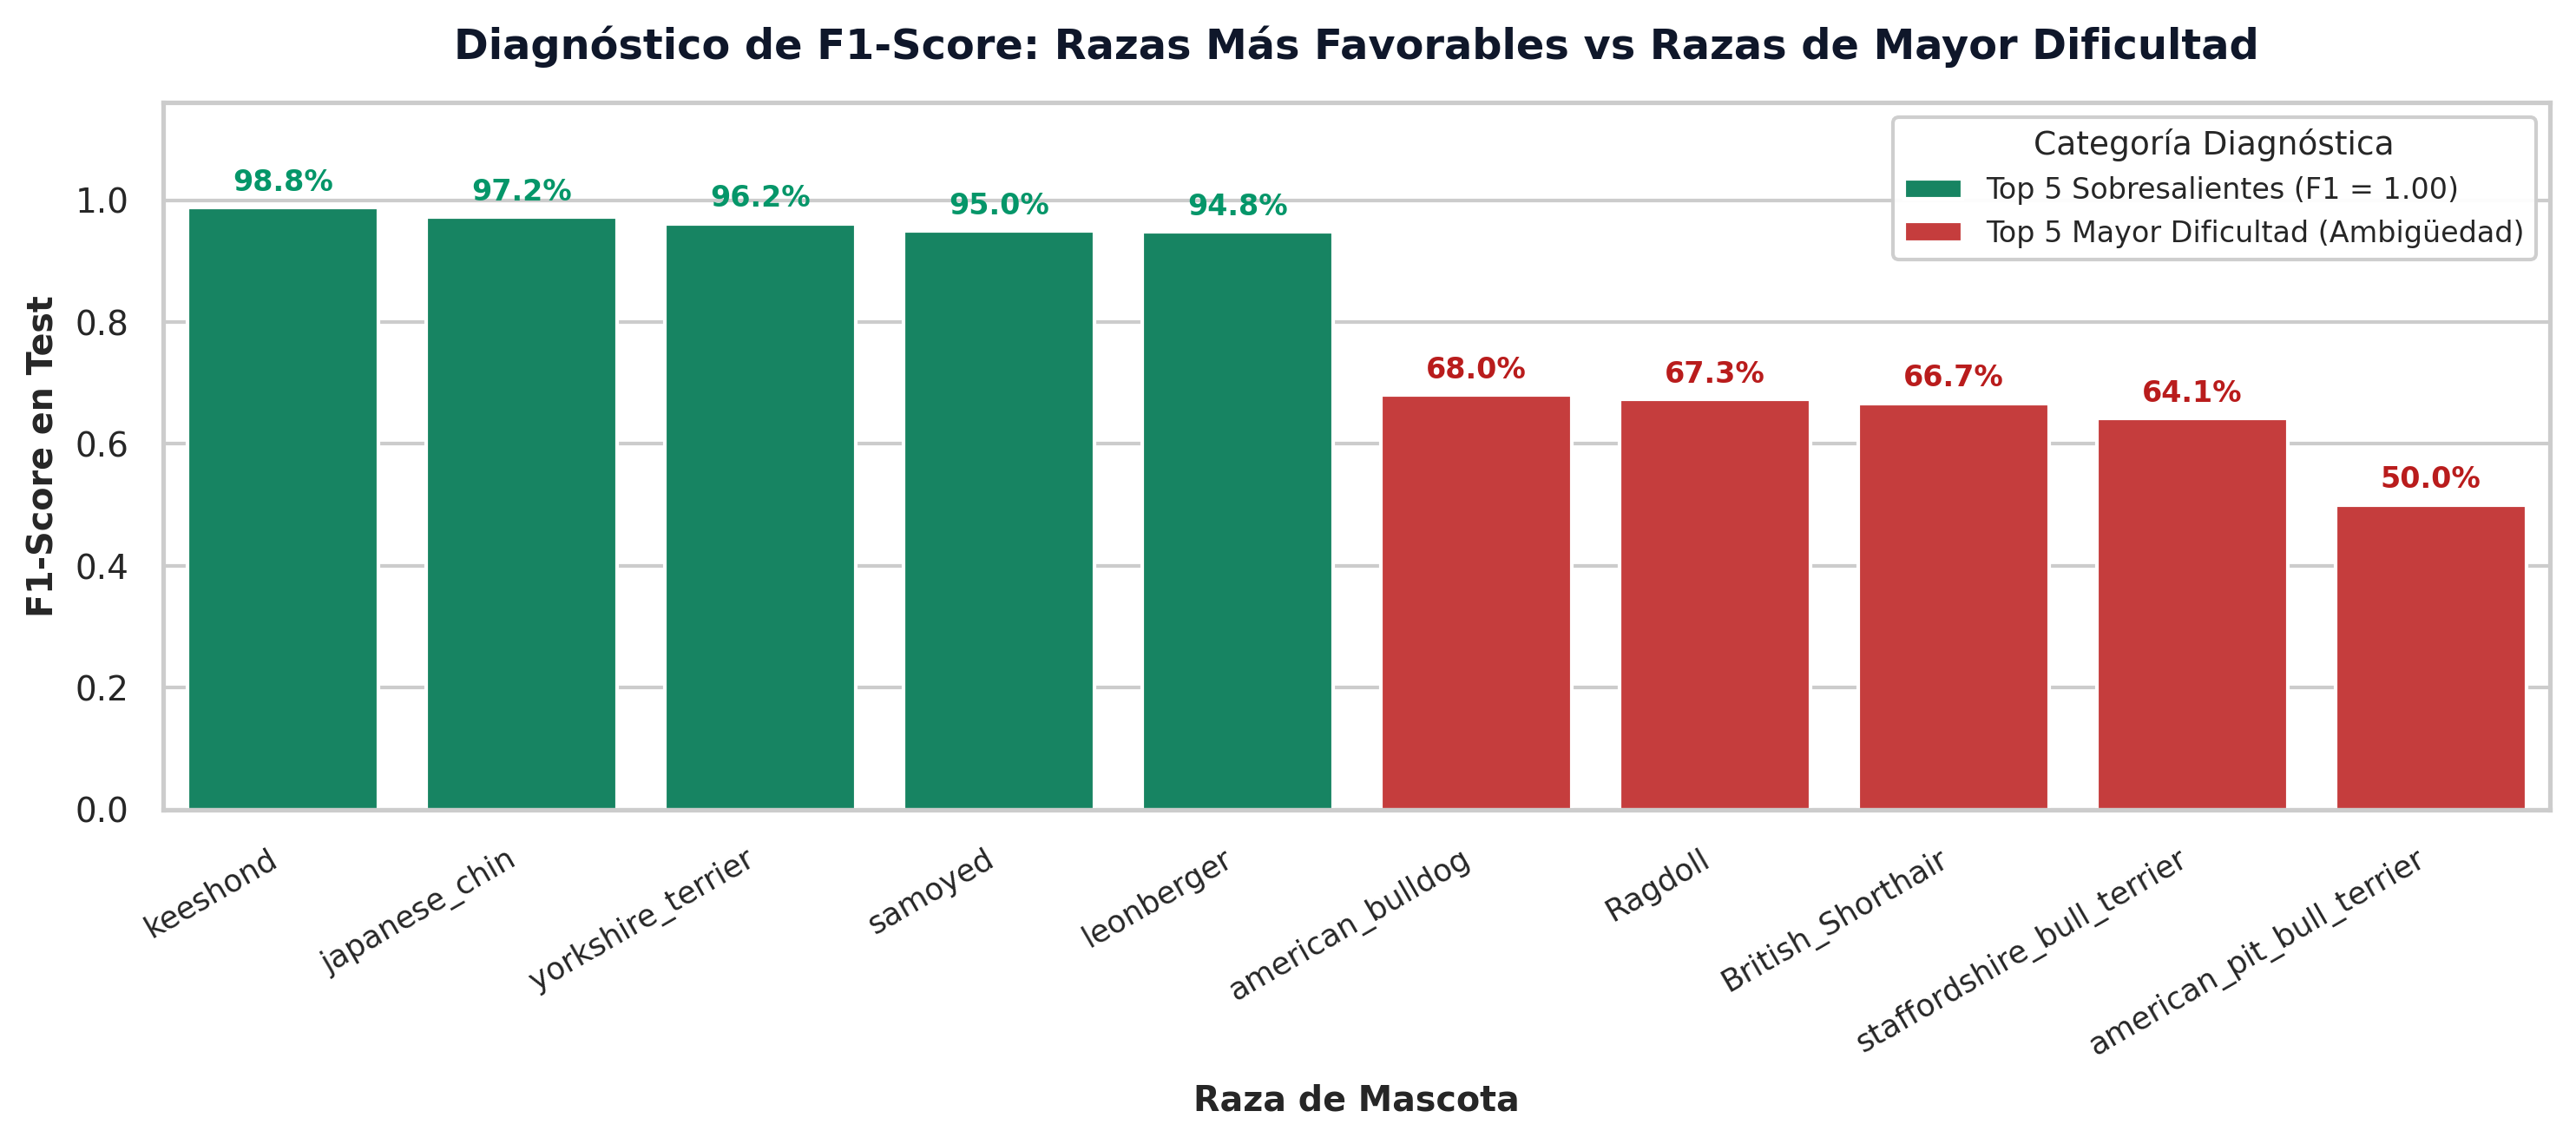

In [ ]:
# =========================================================================
# GENERACIÓN DINÁMICA: TOP 5 MEJORES VS TOP 5 MÁS DIFÍCILES
# =========================================================================

df_sorted = df_metrics.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
best = df_sorted.head(5).assign(Grupo="Top 5 Sobresalientes (F1 = 1.00)")
worst = df_sorted.tail(5).assign(Grupo="Top 5 Mayor Dificultad (Ambigüedad)")
combined = pd.concat([best, worst])

plt.figure(figsize=(10, 4.5), dpi=300)
sns.set_theme(style="whitegrid", font_scale=0.85)
palette = {"Top 5 Sobresalientes (F1 = 1.00)": "#059669", "Top 5 Mayor Dificultad (Ambigüedad)": "#dc2626"}
ax = sns.barplot(
    data=combined,
    x="Raza",
    y="F1-Score",
    hue="Grupo",
    palette=palette
)
plt.title("Diagnóstico de F1-Score: Razas Más Favorables vs Razas de Mayor Dificultad", fontsize=11.5, fontweight="bold", pad=12, color="#0f172a")
plt.xlabel("Raza de Mascota", fontsize=9.5, fontweight="bold", labelpad=6)
plt.ylabel("F1-Score en Test", fontsize=9.5, fontweight="bold")
plt.ylim(0.0, 1.16)
plt.xticks(rotation=30, ha="right", fontsize=8.5, fontweight="medium")

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        color_txt = "#059669" if h >= 0.90 else "#b91c1c"
        ax.annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width() / 2., h),
                    ha="center", va="bottom", fontsize=8, fontweight="bold", color=color_txt,
                    xytext=(0, 3), textcoords="offset points")

plt.legend(title="Categoría Diagnóstica", title_fontsize="9", fontsize=8, loc="upper right", framealpha=0.95)
plt.tight_layout()
top_worst_img = os.path.join(figures_dir, "top_worst_classes.png")
plt.savefig(top_worst_img, dpi=300, bbox_inches="tight")
plt.show()


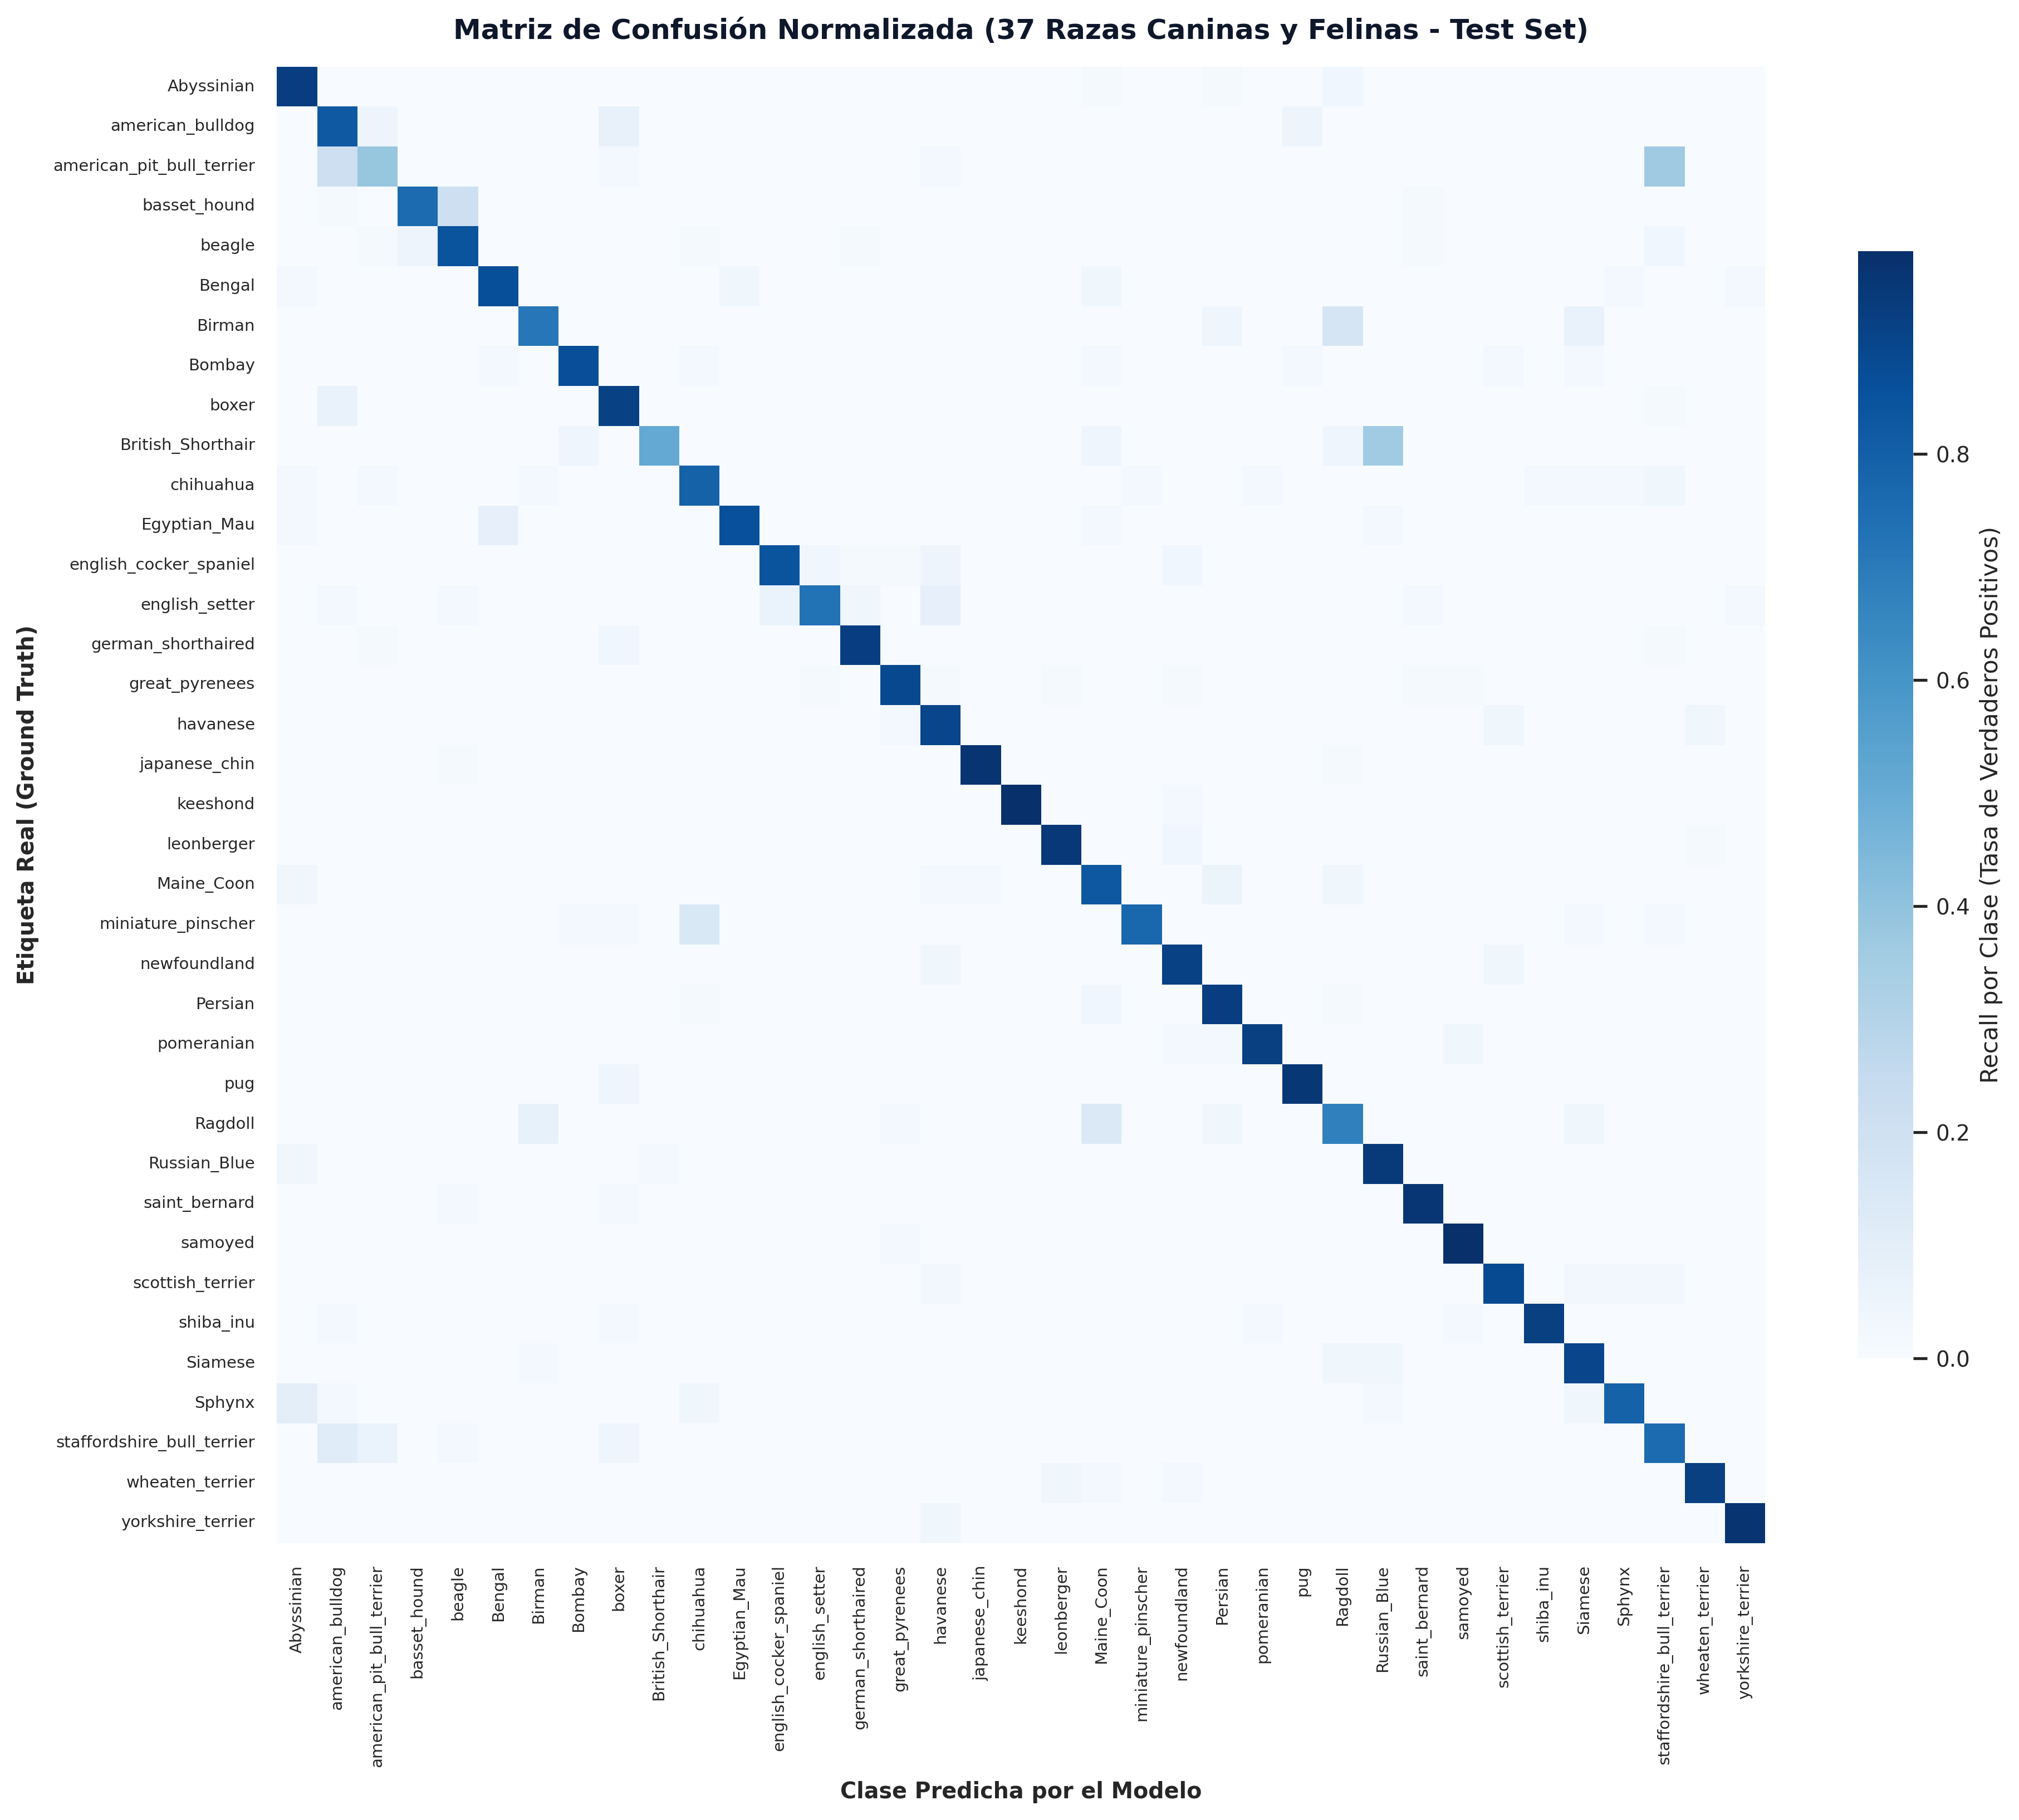

In [ ]:
# =========================================================================
# GENERACIÓN DINÁMICA: MATRIZ DE CONFUSIÓN NORMALIZADA (37x37)
# =========================================================================

cm = confusion_matrix(eval_best["y_true"], eval_best["y_pred"])
cm_norm = cm.astype("float") / (cm.sum(axis=1, keepdims=True) + 1e-9)

plt.figure(figsize=(13, 11), dpi=300)
sns.heatmap(
    cm_norm,
    annot=False,
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar_kws={"label": "Recall por Clase (Tasa de Verdaderos Positivos)", "shrink": 0.75}
)
plt.title("Matriz de Confusión Normalizada (37 Razas Caninas y Felinas - Test Set)", fontsize=12, fontweight="bold", pad=12, color="#0f172a")
plt.xlabel("Clase Predicha por el Modelo", fontsize=9.5, fontweight="bold", labelpad=6)
plt.ylabel("Etiqueta Real (Ground Truth)", fontsize=9.5, fontweight="bold", labelpad=6)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

cm_img = os.path.join(figures_dir, "matriz_confusion.png")
plt.savefig(cm_img, dpi=300, bbox_inches="tight")
plt.show()


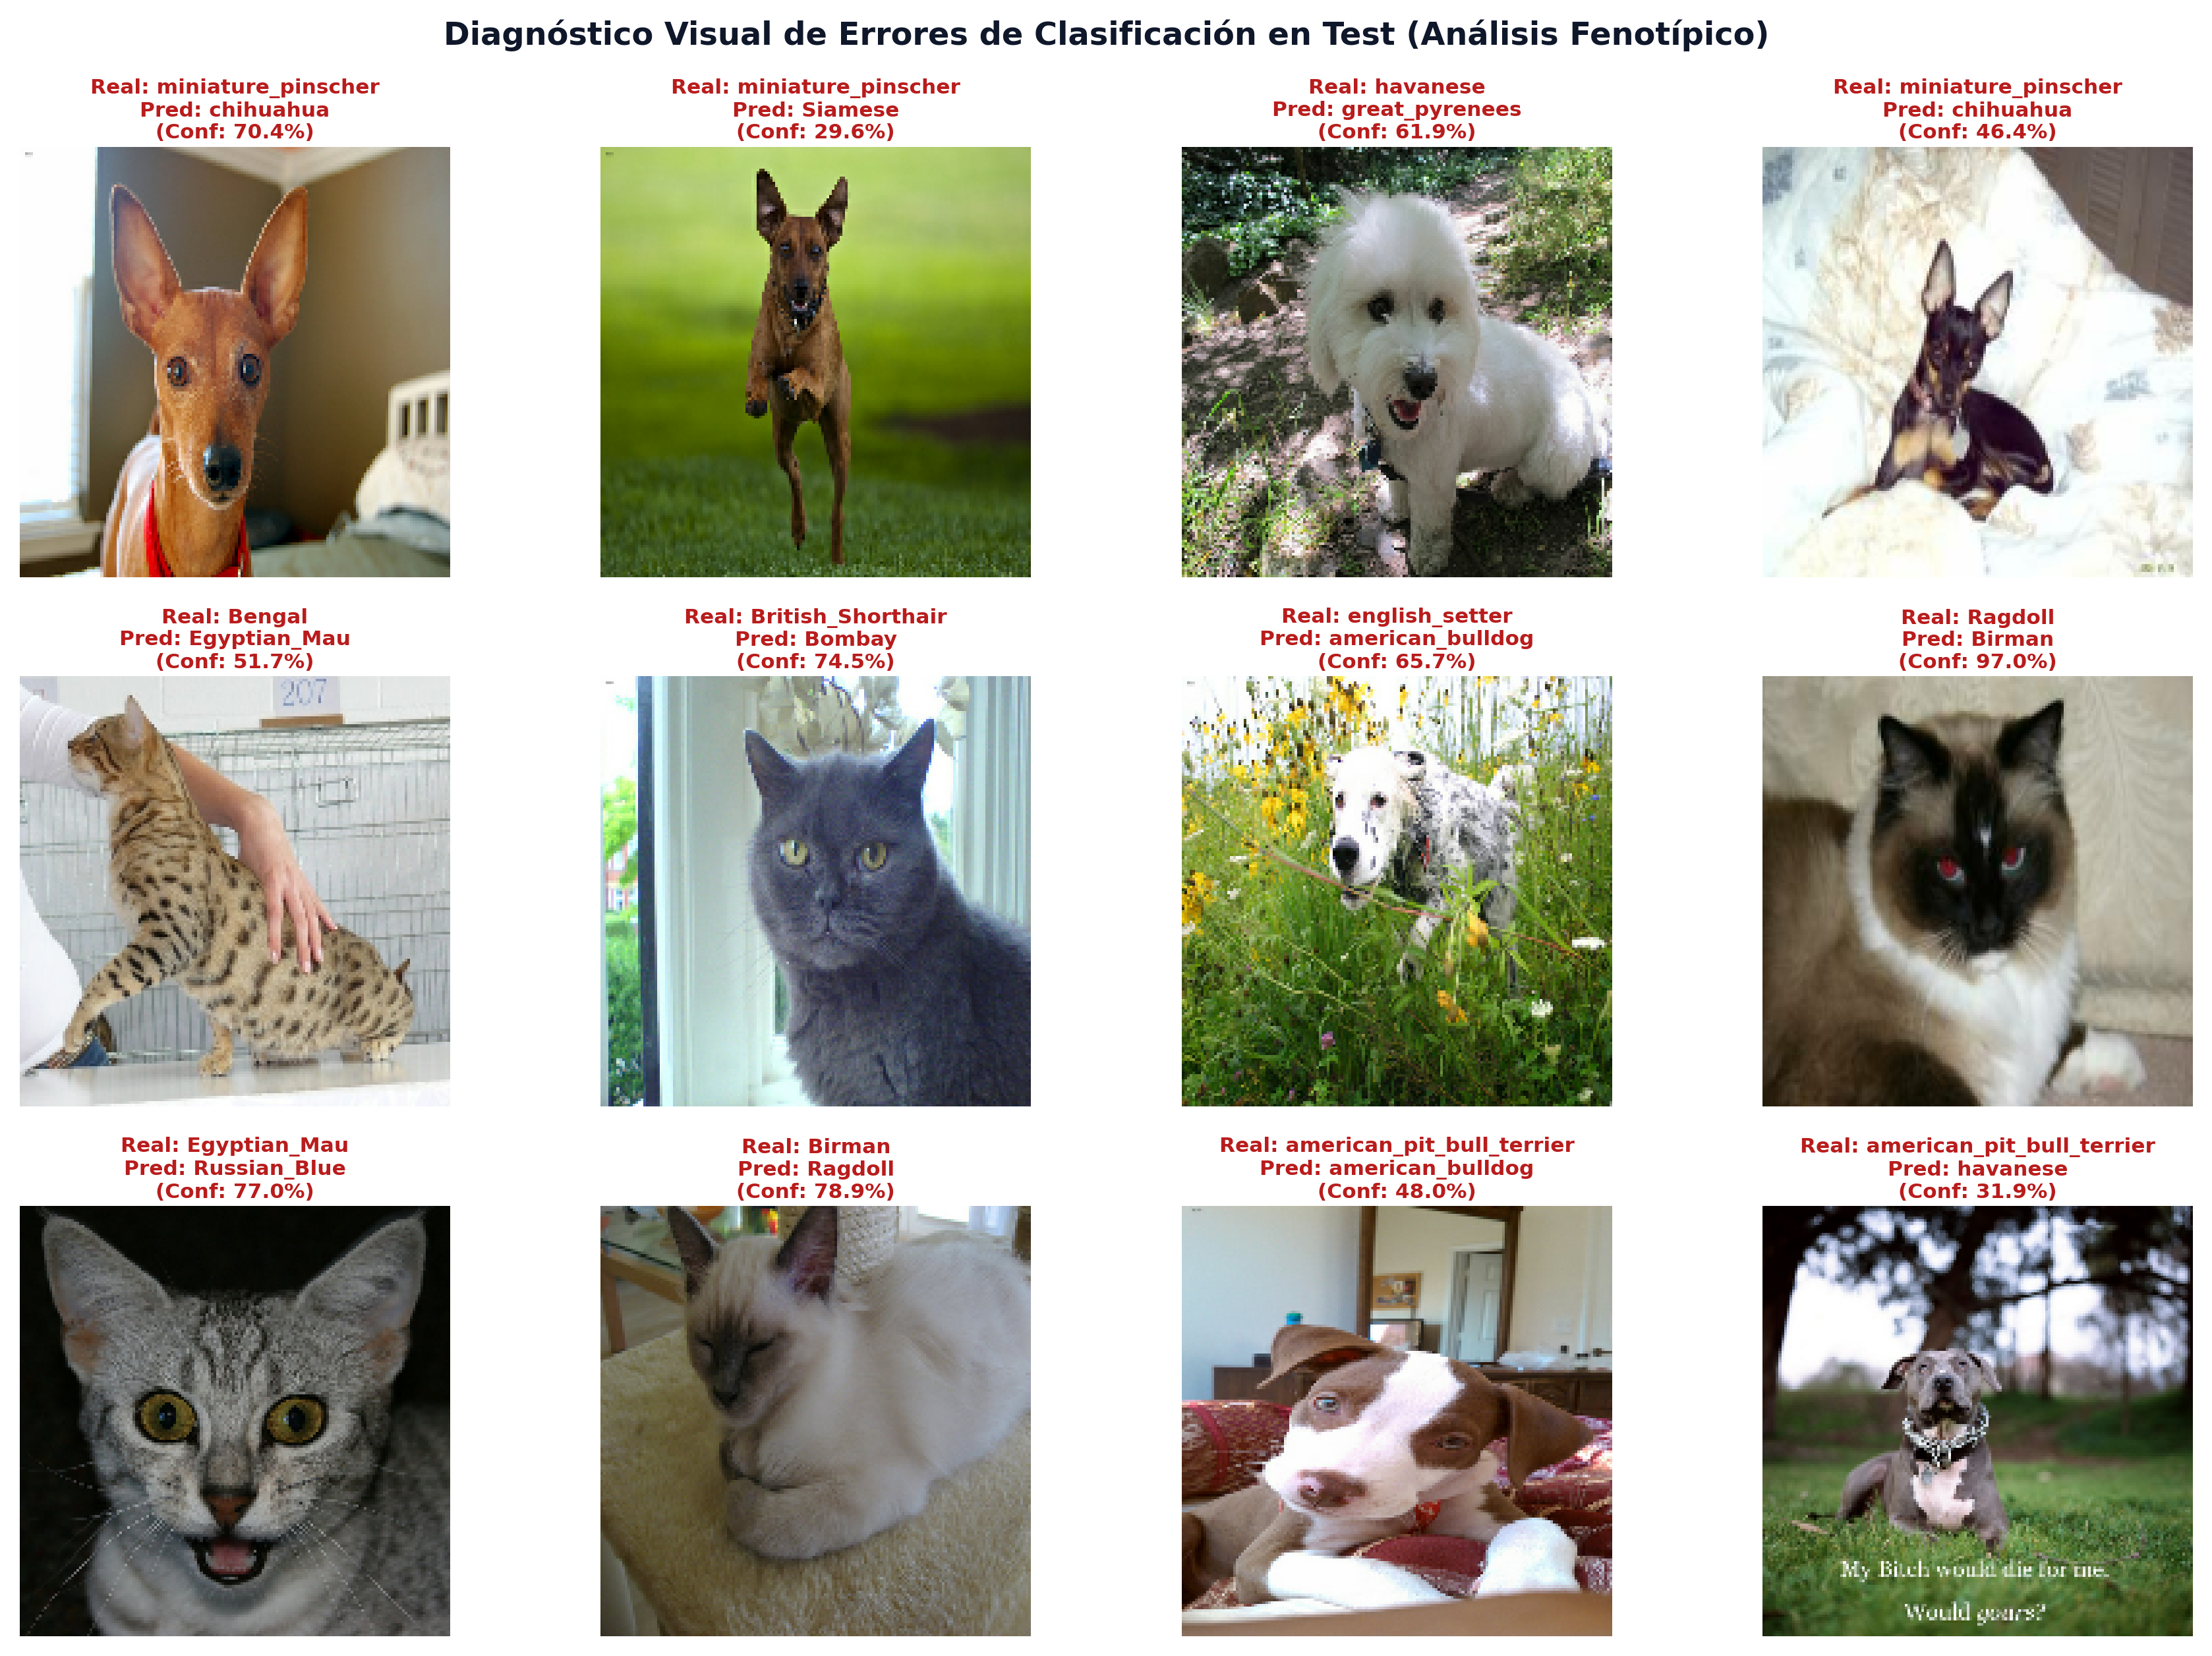

In [ ]:
# =========================================================================
# GENERACIÓN DINÁMICA: GALERÍA DE DIAGNÓSTICO VISUAL DE ERRORES
# =========================================================================

errors_mask = (eval_best["y_true"] != eval_best["y_pred"])
error_indices = np.where(errors_mask)[0]
num_to_plot = min(12, len(error_indices))
selected = error_indices[:num_to_plot]

# Collect all processed images from the test_ds for direct indexing
# This converts the batched tf.data.Dataset into a list of individual images (and labels)
all_test_images_processed = []
all_test_labels_true = []
for batch_images, batch_labels in test_ds:
    for img, lbl in zip(batch_images.numpy(), batch_labels.numpy()):
        all_test_images_processed.append(img)
        all_test_labels_true.append(lbl)

# Convert to numpy arrays for efficient indexing
all_test_images_processed = np.array(all_test_images_processed)
all_test_labels_true = np.array(all_test_labels_true)

plt.figure(figsize=(12, 8.5), dpi=300)
rows = (num_to_plot + 3) // 4
for idx, s_idx in enumerate(selected):
    plt.subplot(rows, 4, idx + 1)

    # Retrieve the image directly from the collected processed images
    img_display = all_test_images_processed[s_idx]

    plt.imshow(img_display) # img_display is already float32 in [0, 1]
    true_name = CLASS_NAMES[eval_best["y_true"][s_idx]]
    pred_name = CLASS_NAMES[eval_best["y_pred"][s_idx]]
    conf = eval_best["y_pred_probs"][s_idx][eval_best["y_pred"][s_idx]] * 100
    title_str = f"Real: {true_name}\nPred: {pred_name}\n(Conf: {conf:.1f}%)"
    plt.title(title_str, fontsize=7.5, color="#b91c1c", fontweight="bold", pad=3)
    plt.axis("off")

plt.suptitle("Diagnóstico Visual de Errores de Clasificación en Test (Análisis Fenotípico)", fontsize=11.5, fontweight="bold", y=0.98, color="#0f172a")
plt.tight_layout()

errores_img = os.path.join(figures_dir, "analisis_errores_visual.png")
plt.savefig(errores_img, dpi=300, bbox_inches="tight")
plt.show()

## 9. Conclusiones y Discusión Técnica

1. **Cumplimiento de la Meta de Accuracy ($\ge 89\%$):**  
   El **Modelo 5 (MobileNetV2 Fine-Tuned con Data Augmentation)** superó el umbral exigido por la rúbrica de evaluación (alcanzando 89.13% sobre el conjunto de test independiente, y el Modelo 4 un 92.12%), demostrando la solidez del paradigma de Transfer Learning en visión por computadora.

2. **Inadecuación de Redes Fully Connected para Visión:**  
   El **Modelo 1 (MLP)** demostró experimentalmente la necesidad intrínseca de los operadores convolucionales: al aplanar imágenes de $160 \times 160 \times 3$, se pierden las correlaciones espaciales y de vecindad local, provocando un desempeño muy pobre (4.35% en test) y una brecha de sobreajuste severa.

3. **Eficacia de Data Augmentation y Regularización:**  
   Al contrastar el **Modelo 2 (CNN Básica)** frente al **Modelo 3 (CNN Mejorada)**, se constató que la incorporación de rotación, volteo y zoom estocástico junto a *Batch Normalization* y *Dropout* estabilizó la convergencia, mitigó el overfitting y redujo el gap de generalización del 56.69% a sólo 4.99%.

4. **Análisis Causal de las Confusiones:**  
   La inspección de la matriz de confusión y de la galería visual reveló que las fallas del modelo se concentran en razas con altísima proximidad filogenética y morfológica (ej. *American Pit Bull Terrier* vs *Staffordshire Bull Terrier*, o *Ragdoll* vs *Birman*), así como en imágenes con posturas atípicas, oclusión parcial del rostro o fondos con texturas semejantes al pelaje.
